# Mangrove belt width and seaward edge

This notebook makes the mangrove figures and tables (of the MDP425-report) from the Google Earth Engine (GEE) output. It can be used for further analyses. Sections are now defined as A–N, but can be adjusted accordingly in Google Earth and GEE.

**Input** (made with the scripts in `scripts/`):
- `data/gee_data_landsat/<site>/`: `<site>_landsat_mangrove_table.csv`, `<site>_landsat_mangrove_stack.tif`, `<site>_boxes.geojson`
- `data/gee_data_s2/<site>/`: `<site>_s2_mangrove_table.csv`, `<site>_s2_annual_mangrove_table.csv`
- `data/gee_data_calibration/`: `calibration_landsat.csv` and `calibration_s2.csv` (reference points)
- `data/gee_data_study_area/`: `intro_mangrove_<period>.tif` (study area map)

**Output:** figures in `results/figures/`, tables in `results/tables/`.

Periods are named by their middle year. For example, period 2025 represents the seasons (December–April) of 2024–2026.

## 1. Settings

In [38]:
import os
import glob
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patheffects as patheffects
import rasterio
import contextily as ctx
from rasterio.warp import transform as reproject_points
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch
from matplotlib.lines import Line2D
from matplotlib.legend_handler import HandlerTuple
from matplotlib.ticker import MultipleLocator

By default (`SAVE = False`), the notebook only shows the figures and tables, so the files in `results/` (the versions used in the report) are not changed.
Set `SAVE = True` to save them in `results/` again -> this overwrites the files there.

In [39]:
SAVE = False   # True = save the figures and tables in results/ (overwrites the files there)

landsat_dir = '../data/gee_data_landsat'
s2_dir = '../data/gee_data_s2'
fig_dir = '../results/figures'
table_dir = '../results/tables'
calibration_dir = '../data/gee_data_calibration'
study_area_dir = '../data/gee_data_study_area'

if SAVE:
    for folder in (fig_dir, table_dir):
        os.makedirs(folder, exist_ok=True)

Sites as named in GEE and the sections (A–N) they belong to, from north-east to south-west.
Interventions: year of construction and type (PRBW = pile-rock breakwater, SCBW = semi-circular breakwater).

In [40]:
SECTORS = {
    'Line_1': 'A', 'Line_2': 'B', 'Line_3': 'C', 'LaiHoa': 'DE', 'Line_5': 'F',
    'Line_6': 'G', 'Line_7': 'HIJK', 'Line_8': 'L', 'Line_9': 'M', 'Line_10': 'N',
}
ORDER = list(SECTORS.values())
SITE_OF = {sector: site for site, sector in SECTORS.items()}

BUILT = {
    '34A': 2023, '34B': 2020, '35': 2023, '36': 2022, '37': 2024,
    '38A': 2024, '38B': 2024, '49A': 2025, '49B': 2020, '49C': 2020, '49D': 2020,
}
TYPES = {
    '34A': 'PRBW', '34B': 'PRBW', '35': 'PRBW', '36': 'SCBW', '37': 'PRBW',
    '38A': 'PRBW', '38B': 'PRBW', '49A': 'PRBW', '49B': 'PRBW', '49C': 'SCBW', '49D': 'PRBW',
}
CANAL_MOUTH = ['49B', '49C']

# Sub-sections inside D–E and H–K
SUBSECTIONS = {
    ('DE', '34A'): 'E', ('DE', '34B'): 'D', ('DE', 'none'): 'D',
    ('HIJK', '49A'): 'K', ('HIJK', '49B'): 'J', ('HIJK', '49C'): 'I', ('HIJK', '49D'): 'H', ('HIJK', 'none'): 'H',
}
# 49B is shorter than one box, so it is added to the figure by hand (km from the start of H)
EXTRA_RUNS = {'HIJK': [('49B', 2.71, 2.80)]}

# Pixel size (m): an edge is only used if the belt is at least one pixel wide
PIXEL_M = {'landsat': 30, 's2': 20, 's2_annual': 20}

Analysis settings:

In [41]:
PERIODS = [1989, 2001, 2013, 2025]   # periods for belt width analysis
MAP_EARLY, MAP_LATE = 2010, 2025     # periods for figures per section

# Trends of the seaward edge (Landsat): name, first period, last period, line style
TRENDS = [
    ('1990–2010 (Landsat)', 1989, 2010, '--'),
    ('2010–2026 (Landsat)', 2010, 2025, '-'),
]
WINDOWS = [('1988–2010', 1989, 2010), ('2010–2019', 2010, 2019), ('2010–2026', 2010, 2025)]

MIN_POINTS = 3          # minimum number of periods for a trend per box
SMOOTH_BOXES = 3        # running median over boxes in the change rate plot
MIN_BELT = 500          # target belt width for wave damping (m)
MIN_PERIODS_TURN = 8    # minimum number of periods with an edge for the turning period

ZONES = {'A–B': ['A', 'B'], 'C': ['C'], 'DE–N': ['DE', 'F', 'G', 'HIJK', 'L', 'M', 'N']}
THRESHOLDS = {'landsat': (4, 0.3), 's2': (2.75, 0.3)}   # MVI and NDVI

Figure style:

In [42]:
GREEN = '#2e8b57'
EARLY_COLOUR = '#b7e4a7'
LATE_COLOUR = '#006d2c'
S2_COLOUR = '#9f57c1'
ACCRETION_COLOURS = ['#8abee0', '#468cc8', '#1152aa']
EROSION_COLOURS = ['#f88e7a', '#dc4c48', '#a51314']
S2_STYLE = ':'

GRID_M, GRID_M_LONG, LONG_SECTOR_KM = 200, 1000, 8   # grid lines every box, or every km for long sections

MAP_CREDIT = ('Tiles © Esri — Source: Esri, i-cubed, USDA, USGS, AEX, GeoEye, Getmapping, Aerogrid, '
              'IGN, IGP, UPR-EGP, and the GIS User Community')

plt.rcParams.update({
    'axes.titlesize': 13,
    'axes.labelsize': 10,
    'xtick.labelsize': 9,
    'ytick.labelsize': 9,
    'legend.fontsize': 9,
})

In [43]:
def period_label(year):
    return f'{year - 1}–{year + 1}'


def section_label(sector):
    if len(sector) == 1:
        return f'Section {sector}'
    return f'Sections {sector[0]}–{sector[-1]}'


def short_label(sector):
    return sector if len(sector) == 1 else f'{sector[0]}–{sector[-1]}'


## 2. Data

One row per 200 m box per period. Landsat: 3-year periods 1989–2025. Sentinel-2 (`s2`): 3-year periods 2019–2025.
Sentinel-2 annual (`s2_annual`): single dry seasons 2019–2026.

Belt width = mangrove area / box length. The seaward edge is only used if the belt is at least one pixel wide.

In [44]:
def find_file(name):
    hits = []
    for folder in (landsat_dir, s2_dir, calibration_dir, study_area_dir):
        hits += glob.glob(os.path.join(folder, '**', name), recursive=True)
    if len(hits) != 1:
        raise FileNotFoundError(f'{name}: found {len(hits)} files, expected 1')
    return hits[0]


files = glob.glob(os.path.join(landsat_dir, '**', '*_landsat_mangrove_table.csv'), recursive=True)
files += glob.glob(os.path.join(s2_dir, '**', '*_s2_mangrove_table.csv'), recursive=True)
files += glob.glob(os.path.join(s2_dir, '**', '*_s2_annual_mangrove_table.csv'), recursive=True)

tables = []
for file in sorted(files):
    table = pd.read_csv(file, dtype={'intervention': str})
    name = os.path.basename(file)
    if '_s2_annual_' in name:
        table['sensor'] = 's2_annual'
    elif '_s2_' in name:
        table['sensor'] = 's2'
    else:
        table['sensor'] = 'landsat'
    tables.append(table)

df = pd.concat(tables, ignore_index=True)
df['sector'] = df['site'].map(SECTORS)
df['x_mid'] = (df['x_m'] + df['piece_m'] / 2).round(1)
df['width_m'] = df['mangrove_ha'] * 10000 / df['piece_m']
df['edge'] = df['edge_m'].where(df['width_m'] >= df['sensor'].map(PIXEL_M))

landsat = df[df['sensor'] == 'landsat']
len(df)

7632

Check: number of boxes, periods and the lowest number of images per period, per section and sensor.

In [45]:
check = df.groupby(['sector', 'sensor']).agg(
    boxes=('bin', 'nunique'),
    periods=('period', 'nunique'),
    min_images=('n_images', 'min'),
)
check.unstack('sensor').loc[ORDER]

boxes                periods              min_images              
sensor landsat   s2 s2_annual landsat s2 s2_annual    landsat  s2 s2_annual
sector                                                                     
A           20   20        20      13  3         8         13  41        11
B           42   42        42      13  3         8         13  41        11
C          136  136       136      13  3         8         13  80        17
DE          25   25        25      13  3         8          5  39         8
F           23   23        23      13  3         8          5  39         8
G           16   16        16      13  3         8          5  39         8
HIJK        17   17        17      13  3         8          5  39         8
L            6    6         6      13  3         8          5  39         8
M           22   22        22      13  3         8          5  39         8
N           11   11        11      13  3         8          5  39         8

## 3. Study area map

Landsat true colour with mangrove for four periods. The images are made in GEE (see `gee/`).

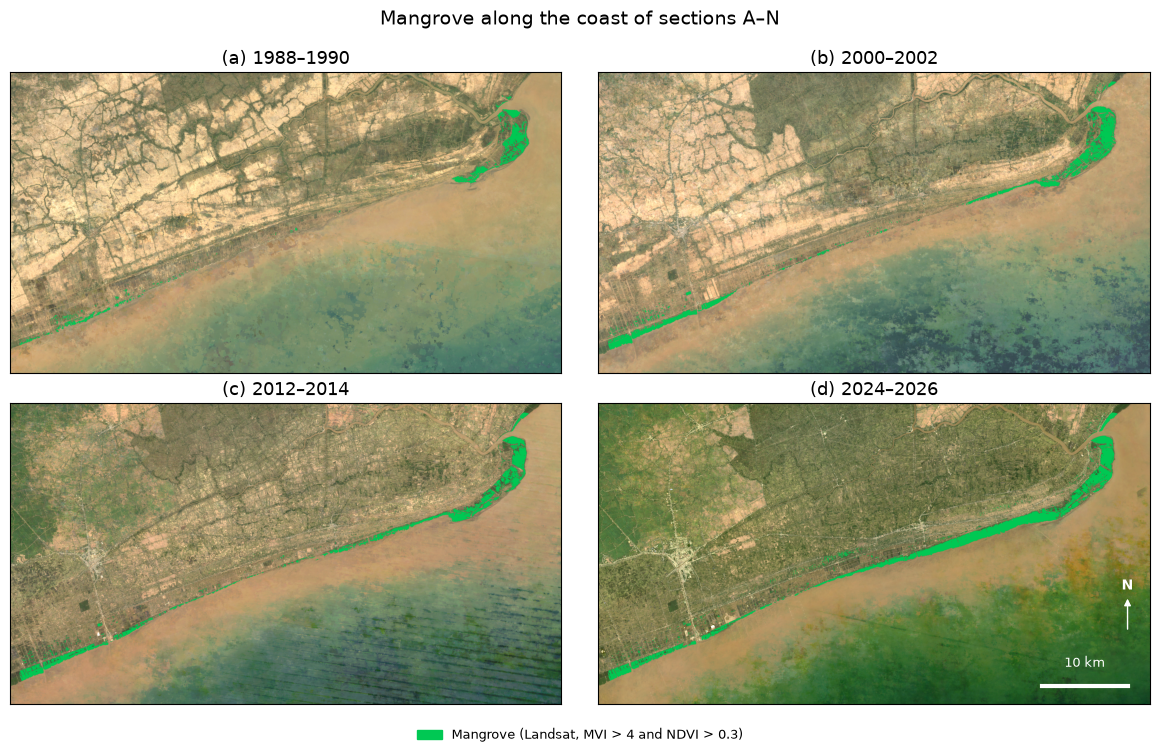

In [46]:
with rasterio.open(find_file(f'intro_mangrove_{PERIODS[0]}.tif')) as src:
    extent = (src.bounds.left, src.bounds.right, src.bounds.bottom, src.bounds.top)
ratio = (extent[1] - extent[0]) / (extent[3] - extent[2])

fig, axes = plt.subplots(2, 2, figsize=(12, 12 / ratio + 1), sharex=True, sharey=True)
axes = axes.ravel()

for ax, period, letter in zip(axes, PERIODS, 'abcd'):
    with rasterio.open(find_file(f'intro_mangrove_{period}.tif')) as src:
        rgb = np.dstack([src.read(band) for band in (1, 2, 3)])
    ax.imshow(rgb, extent=extent)
    ax.set_title(f'({letter}) {period_label(period)}')
    ax.set_xticks([])
    ax.set_yticks([])

# Scale bar and north arrow in the sea of the last map
ax = axes[-1]
bar_x = extent[1] - 0.04 * (extent[1] - extent[0]) - 10000
bar_y = extent[2] + 0.06 * (extent[3] - extent[2])
ax.plot([bar_x, bar_x + 10000], [bar_y, bar_y], color='white', linewidth=3)
ax.text(bar_x + 5000, bar_y, '10 km\n', ha='center', va='bottom', color='white', fontsize=9)
ax.annotate('', xy=(0.96, 0.36), xytext=(0.96, 0.24), xycoords='axes fraction',
            arrowprops=dict(arrowstyle='-|>', color='white'))
ax.text(0.96, 0.37, 'N', transform=ax.transAxes, ha='center', va='bottom', color='white', fontweight='bold')

legend = [Patch(color='#00c853', label='Mangrove (Landsat, MVI > 4 and NDVI > 0.3)')]
fig.legend(handles=legend, loc='lower center', frameon=False)
fig.suptitle('Mangrove along the coast of sections A–N', fontsize=14)
fig.tight_layout(rect=(0, 0.04, 1, 0.97), h_pad=3, w_pad=0.5)
if SAVE:
    fig.savefig(os.path.join(fig_dir, 'mangrove_along_studyarea.png'), dpi=300, bbox_inches='tight')
plt.show()

## 4. Coast frame

Each section is rotated so that the coast is horizontal: `along` runs along the coast, `seaward` points to the sea.
Distances in the figures are in this frame.

In [47]:
def box_corners(site):
    with open(find_file(f'{site}_boxes.geojson')) as f:
        features = json.load(f)['features']

    boxes = []
    for feature in features:
        ring = np.array(feature['geometry']['coordinates'][0][:4])
        x, y = reproject_points('EPSG:4326', 'EPSG:32648', ring[:, 0], ring[:, 1])
        boxes.append({
            'x_m': feature['properties']['x_m'],
            'piece_m': feature['properties']['piece_m'],
            'corners': np.column_stack([x, y]),
        })
    return sorted(boxes, key=lambda box: box['x_m'])


def site_frame(site):
    boxes = box_corners(site)
    first = boxes[0]['corners'].mean(axis=0)
    last = boxes[-1]['corners'].mean(axis=0)
    coast = (last - first) / np.linalg.norm(last - first)

    seaward = np.array([coast[1], -coast[0]])
    if seaward[0] < seaward[1]:
        seaward = -seaward
    along = np.array([seaward[1], -seaward[0]])

    corners = np.vstack([box['corners'] for box in boxes])
    s = corners @ along
    d = corners @ seaward

    return {
        'origin': s.min() * along + d.min() * seaward,
        'along': along,
        'seaward': seaward,
        'length': s.max() - s.min(),
        'depth': d.max() - d.min(),
        'flip': coast @ along < 0,
        'x_start': boxes[0]['x_m'],
        'x_end': boxes[-1]['x_m'] + boxes[-1]['piece_m'],
    }


def to_km(x_m, frame):
    if frame['flip']:
        return (frame['x_end'] - x_m) / 1000
    return (x_m - frame['x_start']) / 1000


def sample_map(path, bands, frame, d_min, d_max, step=5):
    '''Read raster bands on a regular grid (step in m) in the rotated frame.'''
    s = np.arange(0, frame['length'], step) + step / 2
    d = np.arange(d_min, d_max, step) + step / 2
    s_grid, d_grid = np.meshgrid(s, d)
    x = frame['origin'][0] + s_grid * frame['along'][0] + d_grid * frame['seaward'][0]
    y = frame['origin'][1] + s_grid * frame['along'][1] + d_grid * frame['seaward'][1]

    with rasterio.open(path) as src:
        names = list(src.descriptions)
        rows, cols = rasterio.transform.rowcol(src.transform, x.ravel(), y.ravel())
        rows = np.array(rows).reshape(x.shape)
        cols = np.array(cols).reshape(x.shape)
        inside = (rows >= 0) & (rows < src.height) & (cols >= 0) & (cols < src.width)

        layers = []
        for band in bands:
            data = src.read(names.index(band) + 1).astype(float)
            layer = np.full(x.shape, np.nan)
            layer[inside] = data[rows[inside], cols[inside]]
            layers.append(layer)
    return layers, d_grid

## 5. Background images (Esri World Imagery)

The Esri satellite images behind the section maps are downloaded once with `contextily` and saved in `data/gee_data_s2/<site>`.
They are not shared in this repository, due to Esri terms of use.

In [48]:
def download_esri(site, zoom=15, margin_m=1500):
    corners = np.vstack([box['corners'] for box in box_corners(site)])
    x_min, y_min = corners.min(axis=0) - margin_m
    x_max, y_max = corners.max(axis=0) + margin_m
    lon, lat = reproject_points('EPSG:32648', 'EPSG:4326', [x_min, x_max], [y_min, y_max])

    img, extent = ctx.bounds2img(lon[0], lat[0], lon[1], lat[1], zoom=zoom, ll=True,
                                 source=ctx.providers.Esri.WorldImagery)
    img, extent = ctx.warp_tiles(img, extent, t_crs='EPSG:32648')
    left, right, bottom, top = extent
    height, width = img.shape[:2]

    transform = rasterio.transform.from_bounds(left, bottom, right, top, width, height)
    with rasterio.open(esri_path(site), 'w', driver='GTiff', width=width, height=height, count=3,
                       dtype='uint8', crs='EPSG:32648', transform=transform) as dst:
        for band in range(3):
            dst.write(img[:, :, band].astype('uint8'), band + 1)
        dst.descriptions = ('red', 'green', 'blue')
    print('saved', esri_path(site))


def esri_path(site):
    return os.path.join(s2_dir, site, f'{site}_esri_stack.tif')


for site in SECTORS:
    if not os.path.exists(esri_path(site)):
        download_esri(site)


## 6. Change rate of the seaward edge

Per box: linear regression of the edge position over the periods (m/yr), if the box has an edge in at least `MIN_POINTS` periods.

Sentinel-2 trends behind an intervention start in the year of construction. Boxes without an intervention use
the year of the nearest intervention in the same section.

In [49]:
def edge_trend(rows):
    rows = rows.dropna(subset=['edge'])
    if len(rows) < MIN_POINTS:
        return np.nan
    return np.polyfit(rows['period'], rows['edge'], 1)[0]


def box_rates(rows, first, last):
    part = rows[rows['period'].between(first, last)]
    return part.groupby('x_mid')[['period', 'edge']].apply(edge_trend)


def s2_start_year(site_df, first_year):
    boxes = site_df.drop_duplicates('x_mid').set_index('x_mid')['intervention']
    built = boxes[boxes.isin(list(BUILT)) & ~boxes.isin(CANAL_MOUTH)]

    start = {}
    for x, name in boxes.items():
        if name in CANAL_MOUTH:
            continue
        if name in BUILT:
            start[x] = BUILT[name]
        elif len(built) > 0:
            nearest = built.index[np.argmin(np.abs(built.index - x))]
            start[x] = BUILT[built[nearest]]
        else:
            start[x] = first_year
    return pd.Series(start)


def count_boxes(values):
    return f'b={values.notna().sum()}'

## 7. Figures per section

Each figure has three panels:
1. **Mangrove cover** on the Esri image.
2. **Edge position** per period.
3. **Edge change rate** per box. Landsat before and after 2010, and Sentinel-2 after construction of the intervention.

The x-axis runs from the start of the section (right) to the end (left).

In [50]:
def draw_cover(ax, sector, frame, d_min, d_max):
    site = SITE_OF[sector]
    length_km = frame['length'] / 1000

    rgb, d_grid = sample_map(esri_path(site), ['red', 'green', 'blue'], frame, d_min, d_max)
    rgb = np.dstack(rgb) / 255
    rgb[np.isnan(rgb)] = 1
    (early, late), _ = sample_map(find_file(f'{site}_landsat_mangrove_stack.tif'),
                                  [f'm{MAP_EARLY}', f'm{MAP_LATE}'], frame, d_min, d_max)
    early = (early == 1) & (d_grid >= 0)
    late = (late == 1) & (d_grid >= 0)

    extent = (0, length_km, d_max, d_min)
    ax.imshow(rgb, extent=extent, aspect='auto', interpolation='nearest')
    ax.imshow(np.where(early & ~late, 1, np.nan), extent=extent, aspect='auto', interpolation='nearest',
              cmap=ListedColormap([EARLY_COLOUR]))
    ax.imshow(np.where(late, 1, np.nan), extent=extent, aspect='auto', interpolation='nearest',
              cmap=ListedColormap([LATE_COLOUR]))

    s_km = (np.arange(early.shape[1]) + 0.5) * 5 / 1000
    d_m = d_min + (np.arange(early.shape[0]) + 0.5) * 5
    with plt.rc_context({'hatch.color': EARLY_COLOUR, 'hatch.linewidth': 1.2}):
        ax.contourf(s_km, d_m, (early & late).astype(float), levels=[0.5, 1.5], colors='none', hatches=['////'])
        legend = [Patch(facecolor=EARLY_COLOUR, label=period_label(MAP_EARLY)),
                  Patch(facecolor=LATE_COLOUR, label=period_label(MAP_LATE)),
                  Patch(facecolor=LATE_COLOUR, edgecolor=EARLY_COLOUR, hatch='////', label='both')]
        ax.legend(handles=legend, title='Mangrove', loc='lower left', fontsize=9)

    ax.set_ylim(d_max, d_min)
    ax.set_ylabel('Distance (m)')
    ax.text(0.995, 0.01, MAP_CREDIT, transform=ax.transAxes, ha='right', va='bottom', fontsize=5, color='white')
    ax.set_title(f'Mangrove cover ({section_label(sector)})', fontsize=13)

In [51]:
def draw_edges(ax, land_df, frame, d_min, d_max):
    greens = plt.cm.Greens(np.linspace(0.35, 0.95, len(PERIODS)))
    for colour, period in zip(greens, PERIODS):
        line = land_df[land_df['period'] == period]
        km = to_km(line['x_mid'].values, frame)
        order = np.argsort(km)
        ax.plot(km[order], line['edge'].values[order], color=colour, linewidth=2, marker='o', markersize=3,
                label=f'{period_label(period)} ({count_boxes(line["edge"])})')

    ax.set_ylim(d_min, d_max + 0.7 * (d_max - d_min))
    ax.set_ylabel('Distance (m)')
    ax.set_title('Mangrove edge position', fontsize=13)
    ax.legend(title='Period', loc='upper right', fontsize=9)
    ax.text(0.01, 0.95, 'Sea ↑', transform=ax.transAxes, ha='left', va='top', fontweight='bold')
    ax.text(0.01, 0.05, 'Land ↓', transform=ax.transAxes, ha='left', va='bottom', fontweight='bold')

The change rate per box is the slope of a linear regression of the edge position over time (dots).
The line is a running median of these rates over `SMOOTH_BOXES` neighbouring boxes, only to show the pattern along the coast.
Blue = seaward (expansion), red = landward (retreat).

In [52]:
def plot_rate(ax, km, rate, number, style):
    order = np.argsort(km)
    km, rate = km[order], rate[order]
    line = np.array(pd.Series(rate).rolling(SMOOTH_BOXES, center=True, min_periods=1).median())
    line[np.isnan(rate)] = np.nan

    # Add a point where the line crosses zero, so the colour changes exactly at zero
    x, y = [km[0]], [line[0]]
    for i in range(1, len(km)):
        if line[i - 1] * line[i] < 0:
            x.append(km[i - 1] + (km[i] - km[i - 1]) * line[i - 1] / (line[i - 1] - line[i]))
            y.append(0)
        x.append(km[i])
        y.append(line[i])
    x, y = np.array(x), np.array(y)

    ax.plot(x, np.where(y >= 0, y, np.nan), color=ACCRETION_COLOURS[number], linestyle=style, linewidth=2)
    ax.plot(x, np.where(y <= 0, y, np.nan), color=EROSION_COLOURS[number], linestyle=style, linewidth=2)
    colours = np.where(rate >= 0, ACCRETION_COLOURS[number], EROSION_COLOURS[number])
    ax.scatter(km, rate, s=14, color=colours, zorder=3)


def draw_rates(ax, sector, site_df, frame):
    land_df = site_df[site_df['sensor'] == 'landsat']
    all_km = np.sort(land_df['x_mid'].unique())
    shown, labels, all_rates = [], [], []

    for number, (name, first, last, style) in enumerate(TRENDS):
        rate = box_rates(land_df, first, last).reindex(all_km)
        plot_rate(ax, to_km(all_km, frame), rate.values, number, style)
        shown.append(number)
        labels.append(f'{name} ({count_boxes(rate)})')
        all_rates.append(rate)

    s2_df = site_df[site_df['sensor'] == 's2_annual']
    start = s2_start_year(site_df, s2_df['period'].min())
    s2_df = s2_df[s2_df['period'] >= s2_df['x_mid'].map(start)]
    rate = box_rates(s2_df, s2_df['period'].min(), s2_df['period'].max()).reindex(all_km)
    if rate.notna().any():
        plot_rate(ax, to_km(all_km, frame), rate.values, len(TRENDS), S2_STYLE)
        shown.append(len(TRENDS))
        years = '/'.join(str(int(year)) for year in sorted(start[rate.dropna().index].unique()))
        built_here = [name for name in site_df['intervention'].unique() if name in BUILT and name not in CANAL_MOUTH]
        prefix = 'After intervention, ' if built_here else ''
        labels.append(f'{prefix}{years}–{s2_df["period"].max()} (Sentinel-2) ({count_boxes(rate)})')
        all_rates.append(rate)

    styles = [style for _, _, _, style in TRENDS] + [S2_STYLE]
    handles = [(Line2D([], [], color=ACCRETION_COLOURS[i], linestyle=styles[i], linewidth=2),
                Line2D([], [], color=EROSION_COLOURS[i], linestyle=styles[i], linewidth=2)) for i in shown]
    ax.legend(handles, labels, title='Period', handler_map={tuple: HandlerTuple(ndivide=None)},
              loc='upper right', fontsize=8, handlelength=5)

    limit = np.nanmax(np.abs(pd.concat(all_rates))) * 1.2
    top = limit * 1.7
    ax.set_ylim(-limit, top)
    ax.axhspan(0, top, color='#f2f7fc', zorder=0)
    ax.axhspan(-limit, 0, color='#fdf3f2', zorder=0)
    ax.axhline(0, color='black', linewidth=0.8)
    ax.text(0.01, 0.95, 'Expansion (seaward) ↑', transform=ax.transAxes, ha='left', va='top',
            fontweight='bold', color=ACCRETION_COLOURS[2])
    ax.text(0.01, 0.05, 'Retreat (landward) ↓', transform=ax.transAxes, ha='left', va='bottom',
            fontweight='bold', color=EROSION_COLOURS[2])
    ax.set_ylabel('Change rate (m/year)')
    ax.set_xlabel(f'Distance from start of Section {sector[0]} (km)  ←')

Interventions are drawn as labels in the map and above the change rate, with dashed lines at their boundaries.

In [53]:
def intervention_runs(site_df, frame):
    boxes = site_df.drop_duplicates('bin').sort_values('x_m')
    new_run = boxes['intervention'] != boxes['intervention'].shift()
    runs = []
    for _, run in boxes.groupby(new_run.cumsum()):
        ends = to_km(np.array([run['x_m'].iloc[0], run['x_m'].iloc[-1] + run['piece_m'].iloc[-1]]), frame)
        runs.append((run['intervention'].iloc[0], ends.min(), ends.max()))
    return runs


def run_label(sector, name):
    letter = SUBSECTIONS.get((sector, name), sector if len(sector) == 1 else '')
    if name == 'none':
        return letter
    second = f'{name} (built: {BUILT[name]})'
    return f'{letter}\n{second}' if letter else second


def draw_interventions(axes, sector, site_df, frame):
    ax0, ax1, ax2 = axes
    runs = sorted(intervention_runs(site_df, frame) + EXTRA_RUNS.get(sector, []), key=lambda run: run[1])

    levels, level = [], 0
    for name, start_km, end_km in runs:
        level = level + 1 if end_km - start_km < 0.6 and name != 'none' else 0
        levels.append(level)
    outer = (min(run[1] for run in runs), max(run[2] for run in runs))

    outline = [patheffects.withStroke(linewidth=2.5, foreground='black')]
    for (name, start_km, end_km), level in zip(runs, levels):
        text = run_label(sector, name)
        middle = (start_km + end_km) / 2
        ax0.text(middle, 0.96 - 0.13 * level, text, transform=ax0.get_xaxis_transform(), ha='center', va='top',
                 fontsize=9, fontweight='bold', color='white', path_effects=outline, zorder=7)
        ax2.text(middle, 1.01 + 0.13 * level, text, transform=ax2.get_xaxis_transform(), ha='center', va='bottom',
                 fontsize=9, fontweight='bold', color='#444444')
        for boundary in (start_km, end_km):
            if outer[0] + 0.01 < boundary < outer[1] - 0.01:
                for ax in axes:
                    ax.axvline(boundary, color='white' if ax == ax0 else '#444444', linestyle='--',
                               linewidth=1.2, zorder=3)
    return max(levels)

In [54]:
def plot_sector(sector):
    site = SITE_OF[sector]
    site_df = df[df['site'] == site]
    land_df = site_df[site_df['sensor'] == 'landsat']
    frame = site_frame(site)
    length_km = frame['length'] / 1000
    d_min = -100
    d_max = min(frame['depth'] + 50, land_df['edge'].max() + 150)

    fig, (ax0, ax1, ax2) = plt.subplots(3, 1, figsize=(12, 11.5), sharex=True, layout='constrained',
                                        gridspec_kw={'height_ratios': [1.2, 1.2, 1]})
    draw_cover(ax0, sector, frame, d_min, d_max)
    draw_edges(ax1, land_df, frame, d_min, d_max)
    draw_rates(ax2, sector, site_df, frame)
    levels = draw_interventions((ax0, ax1, ax2), sector, site_df, frame)
    ax2.set_title('Mangrove edge change rate', fontsize=13, pad=28 + 30 * levels)

    grid = GRID_M if length_km <= LONG_SECTOR_KM else GRID_M_LONG
    for ax in (ax1, ax2):
        ax.xaxis.set_minor_locator(MultipleLocator(grid / 1000))
        ax.grid(which='both', alpha=0.3)
    ax2.set_xlim(length_km, 0)

    if SAVE:
        fig.savefig(os.path.join(fig_dir, f'mangrove_sector_{sector}.png'), dpi=300, bbox_inches='tight')
    plt.show()

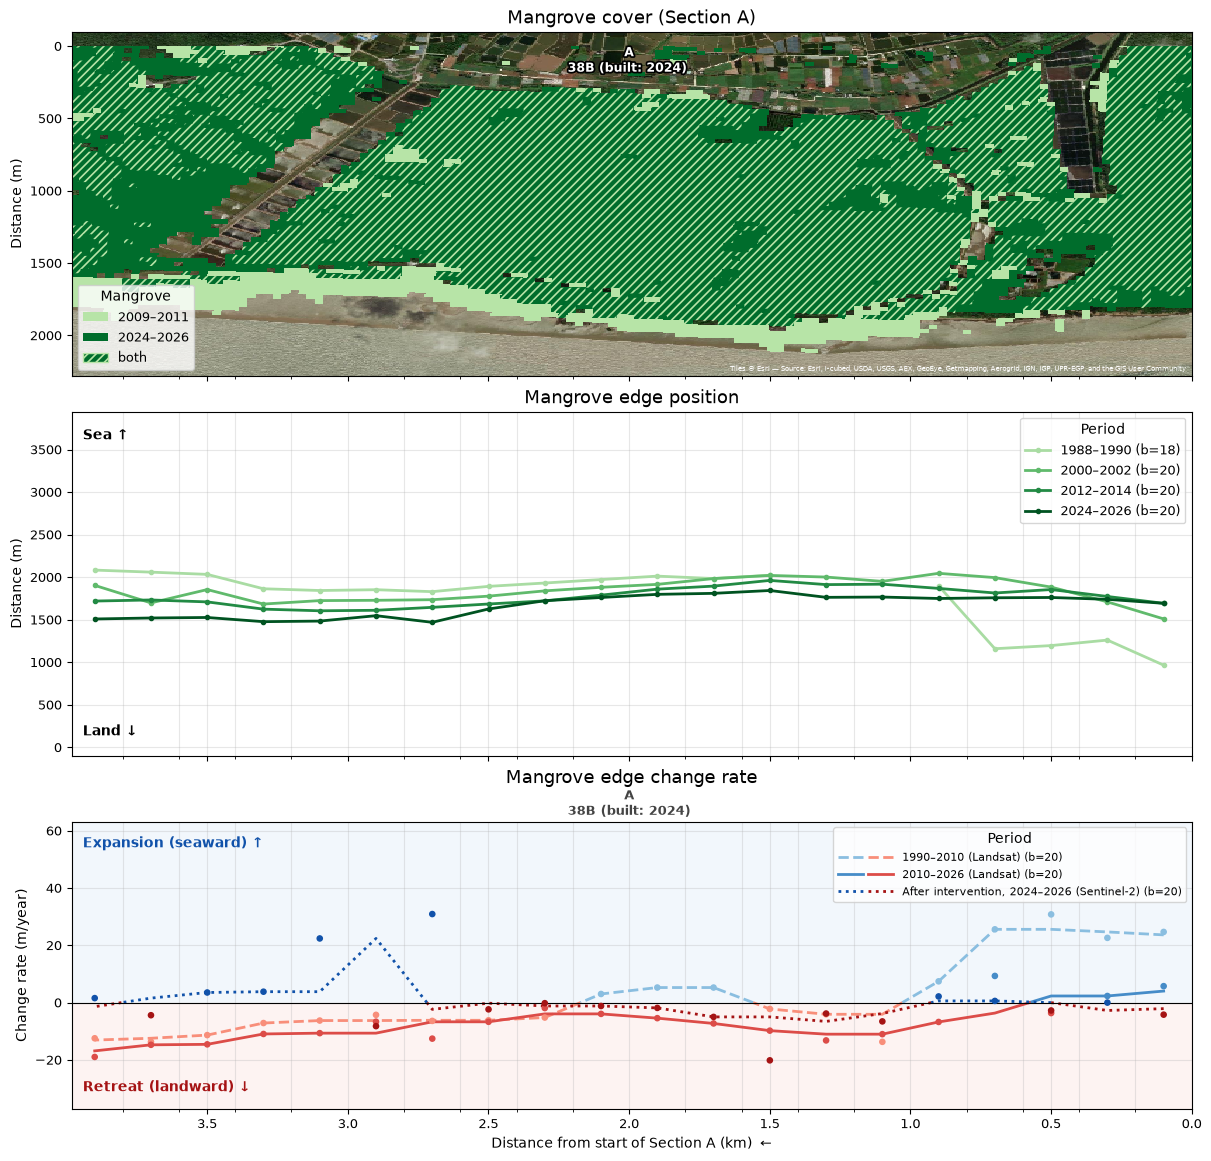

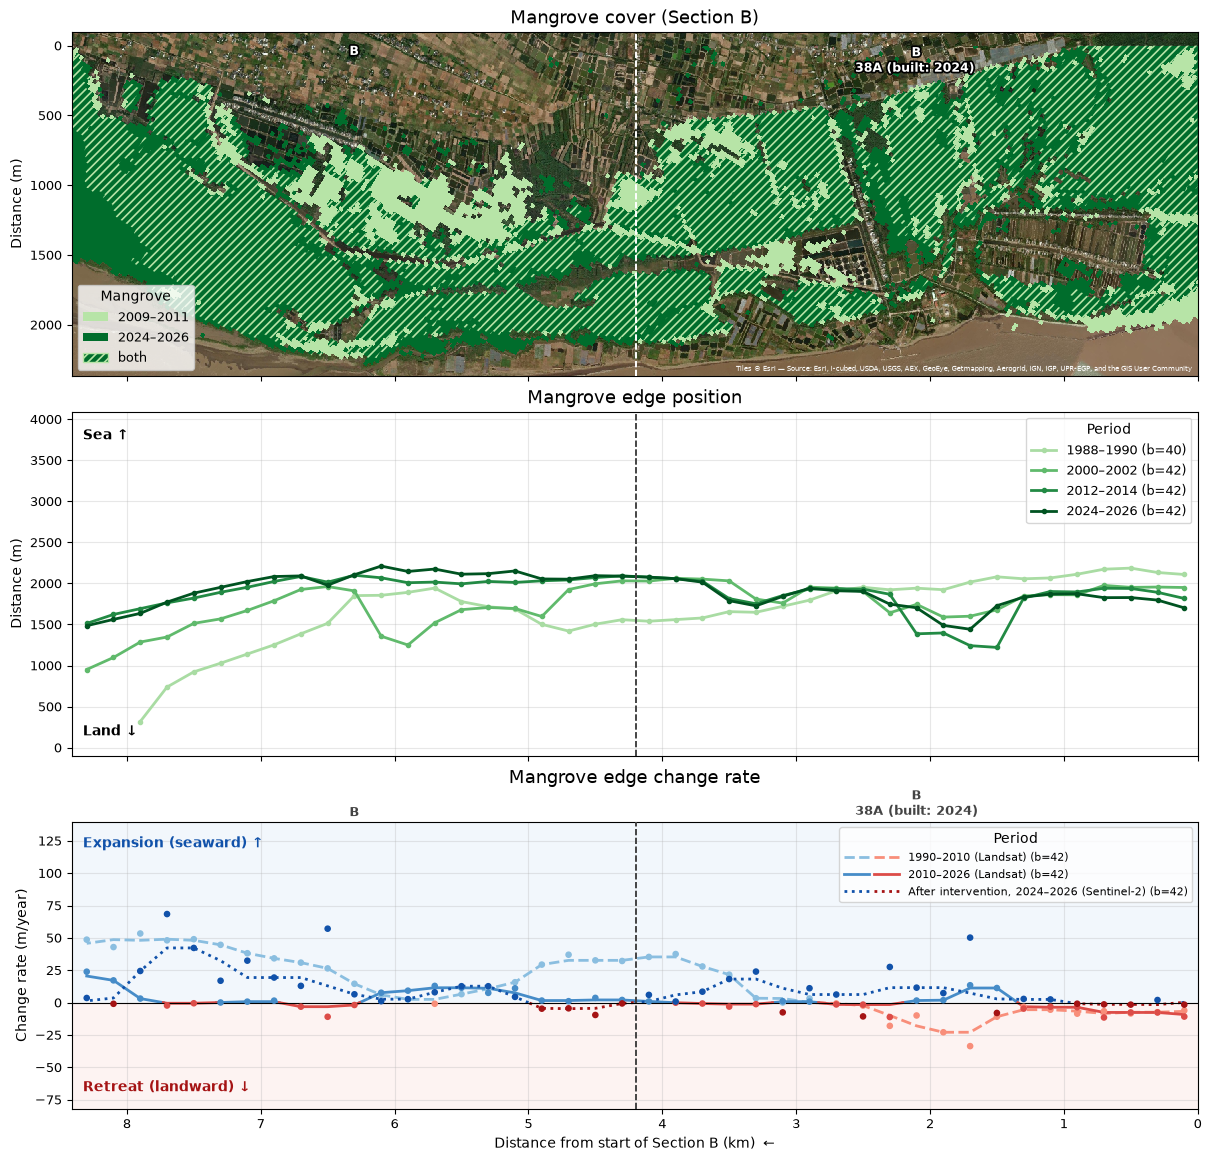

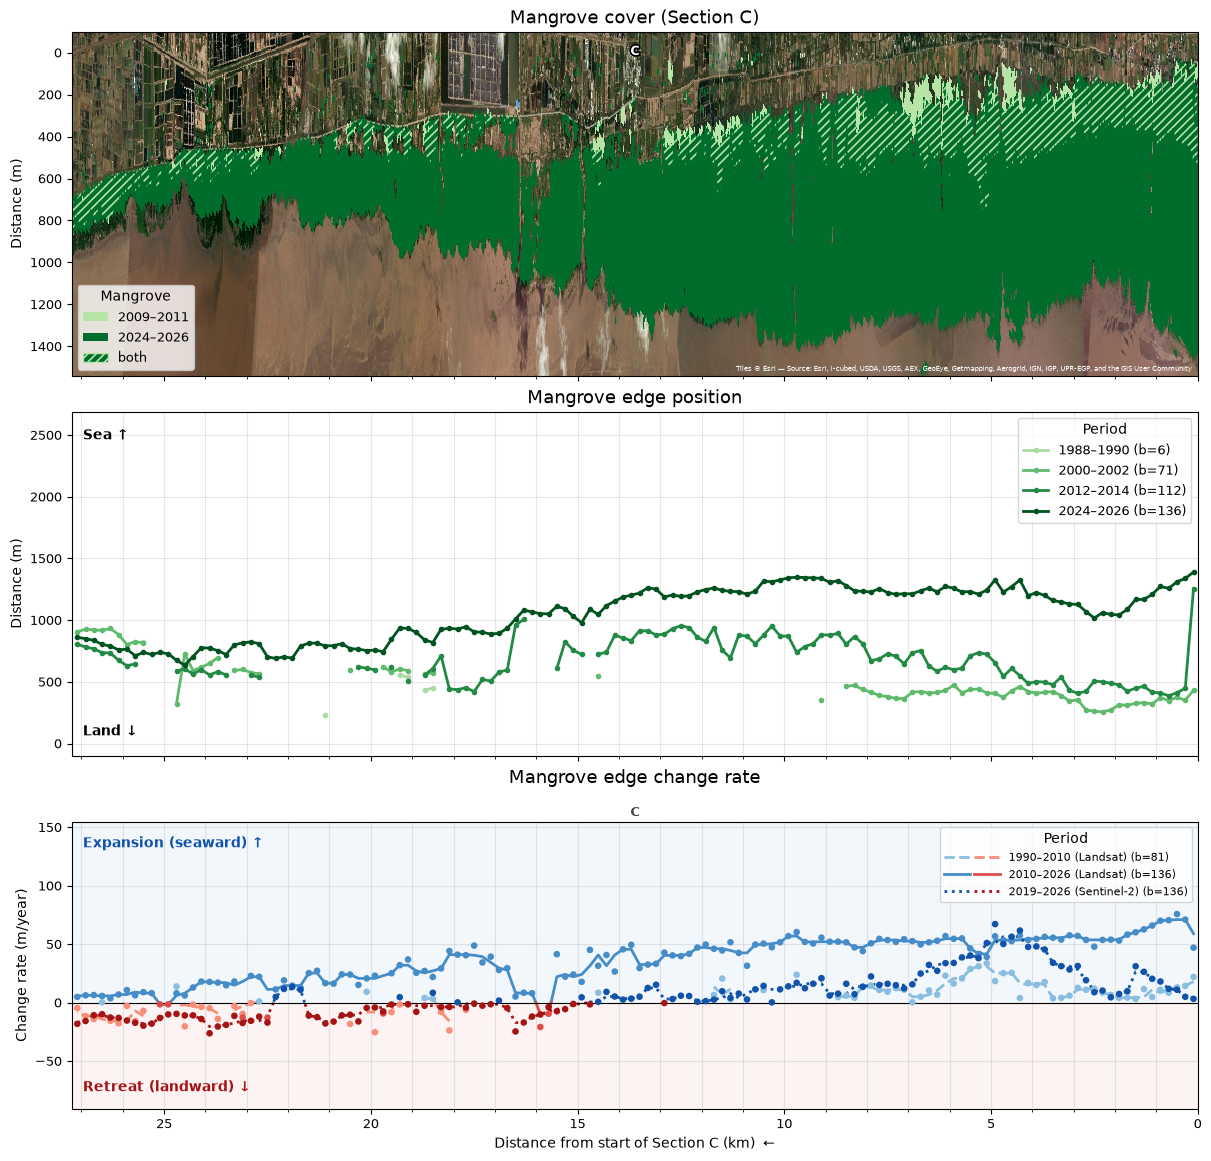

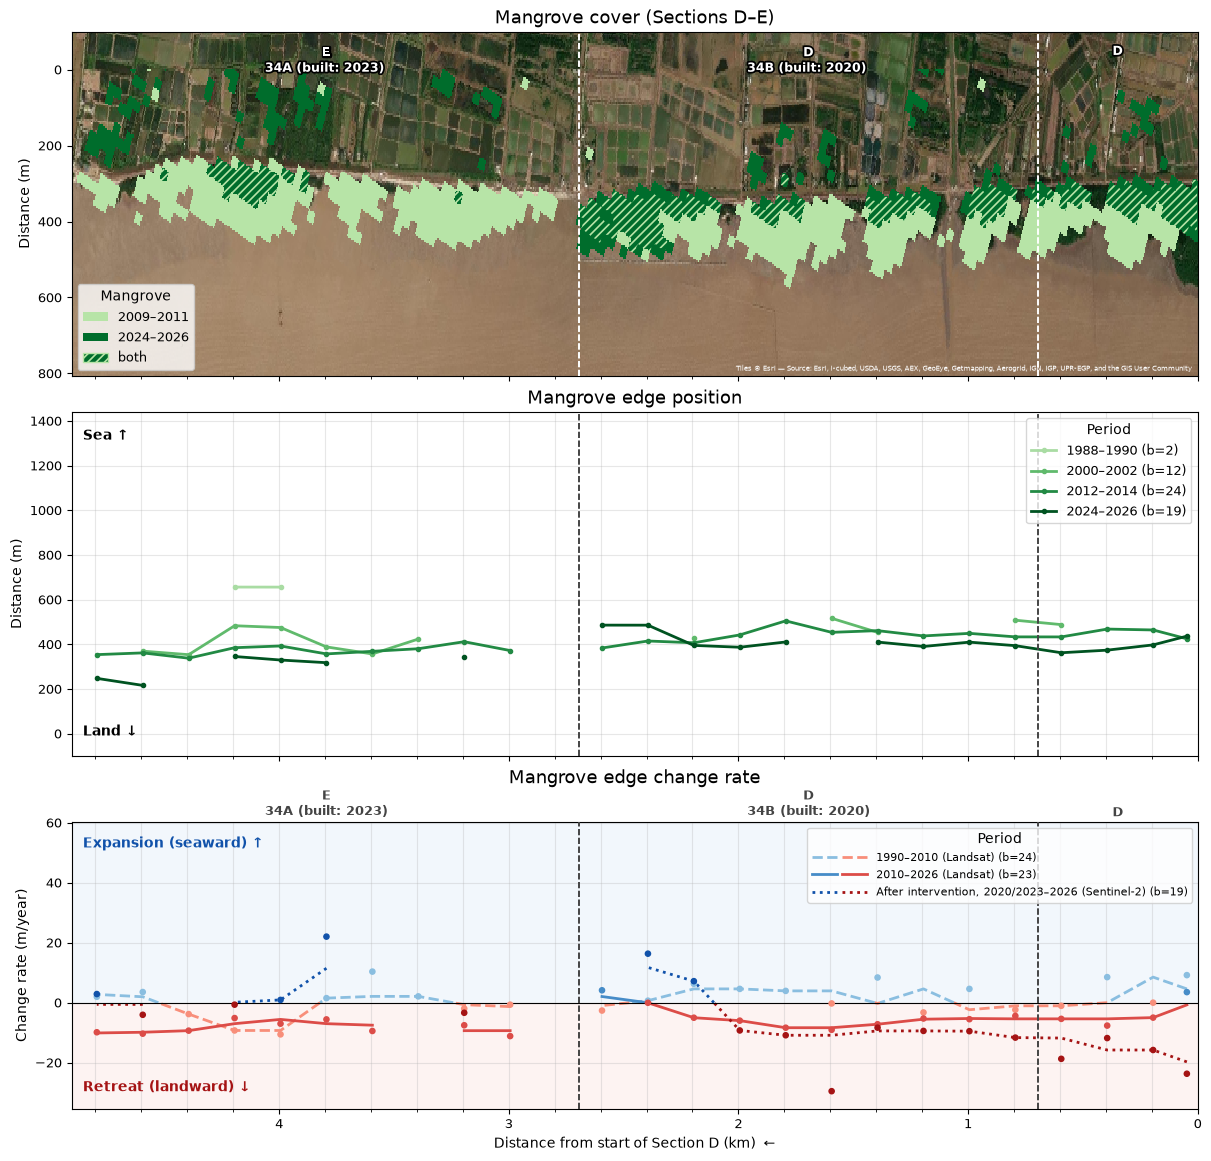

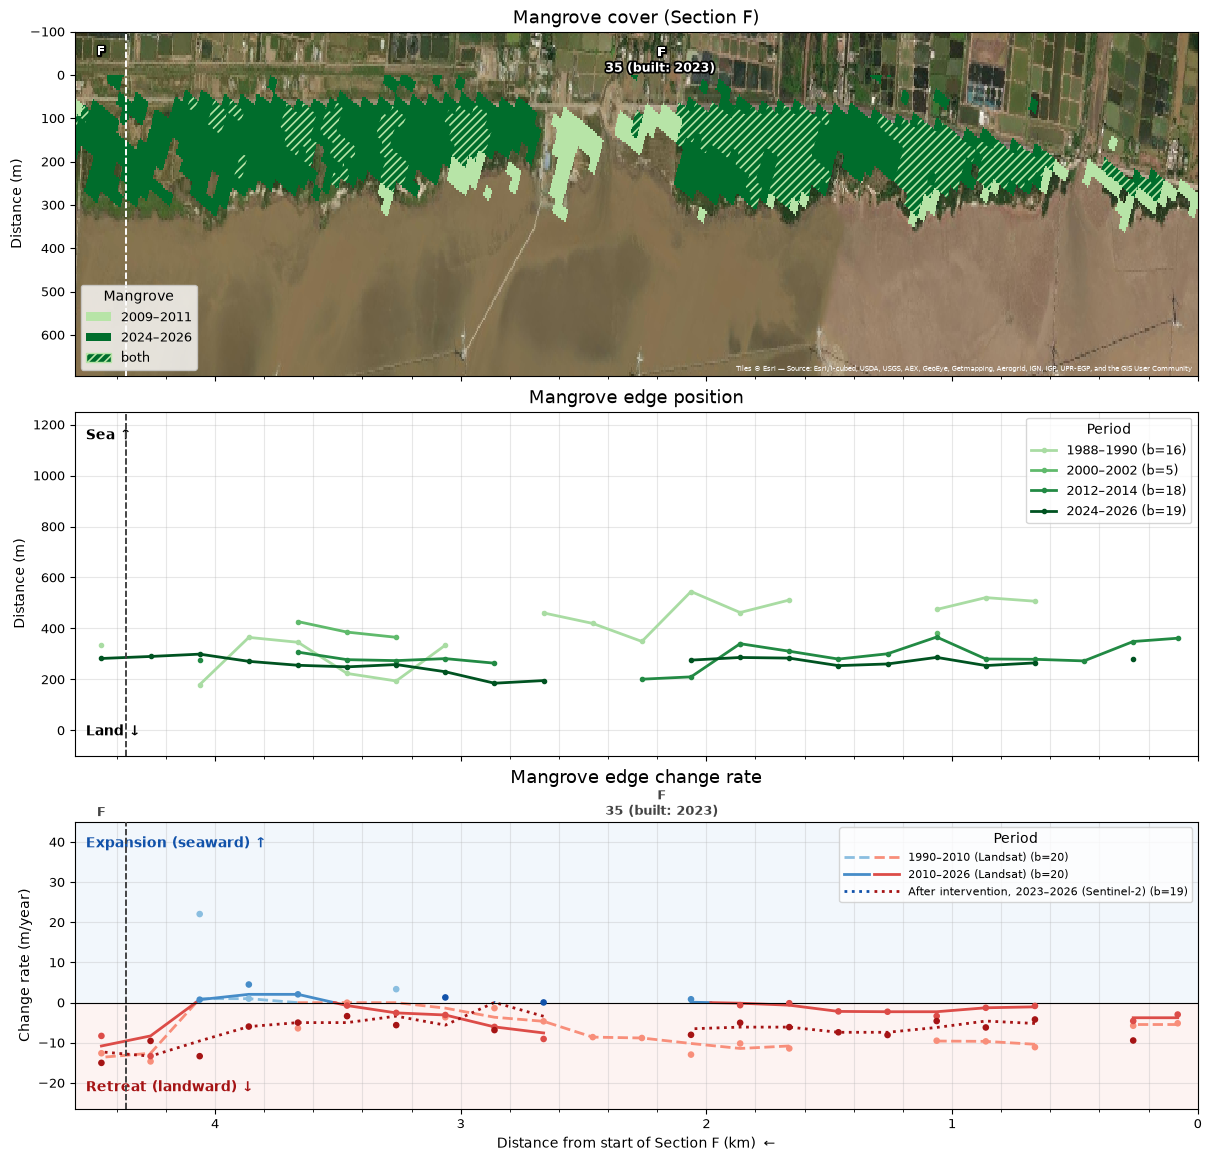

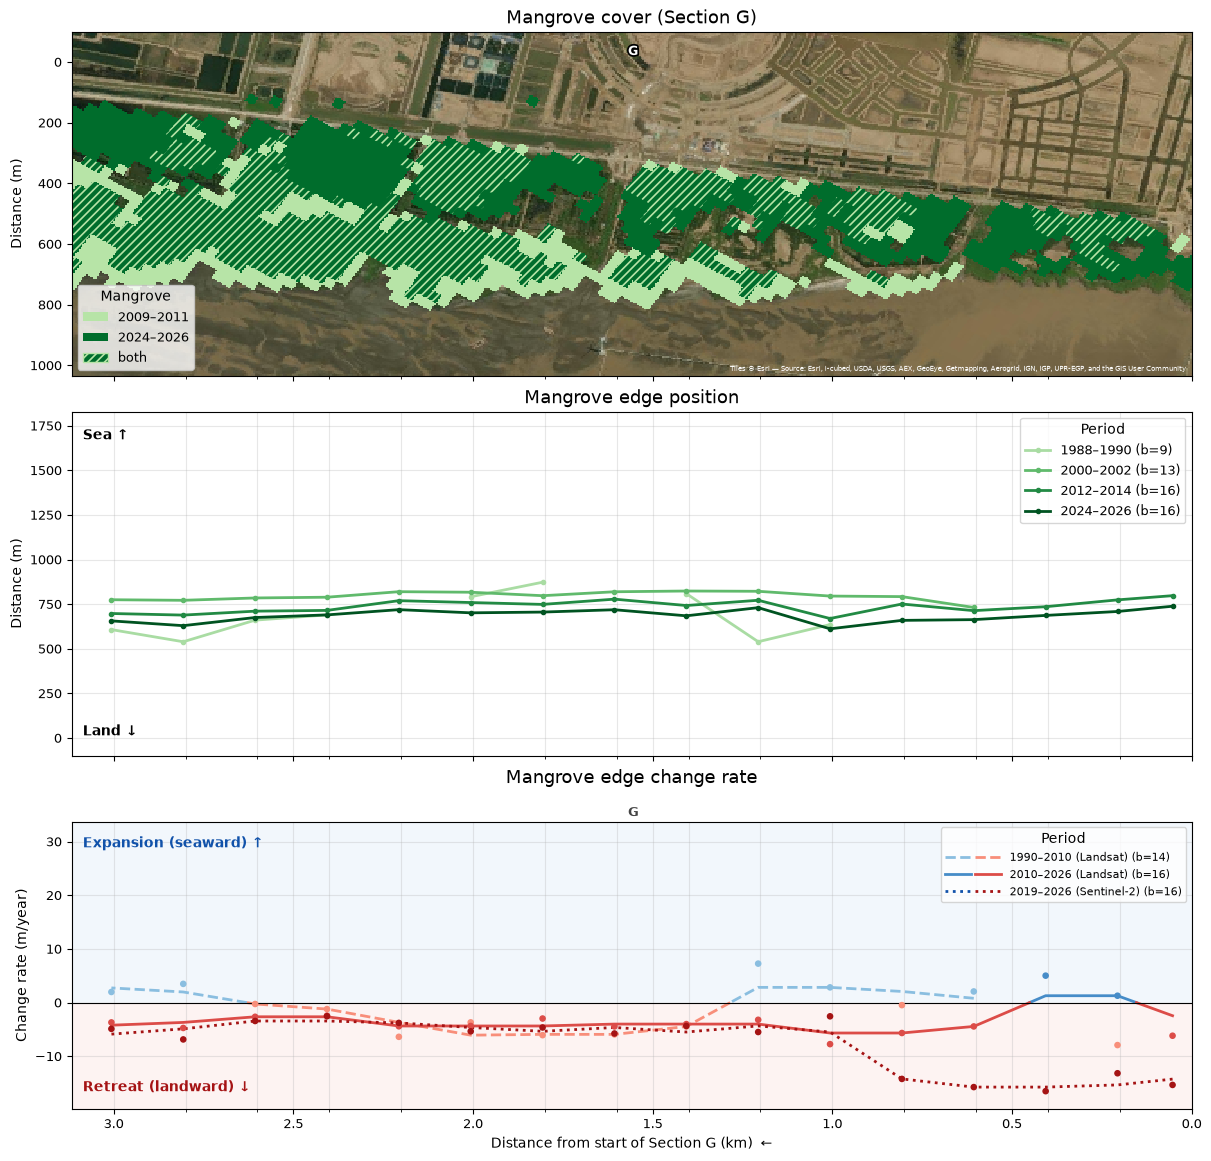

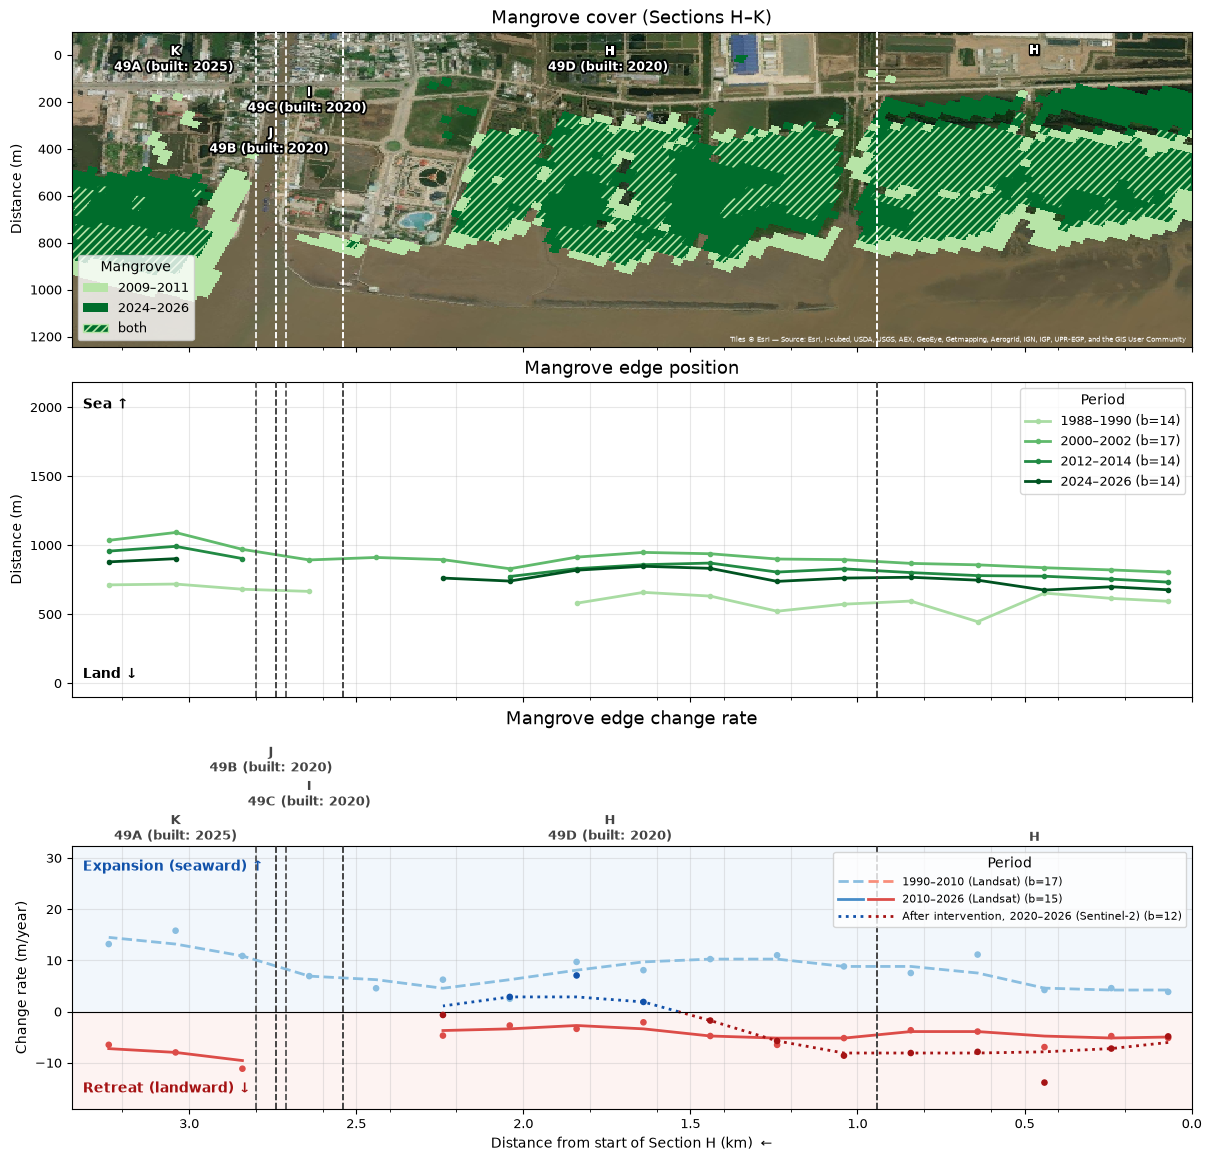

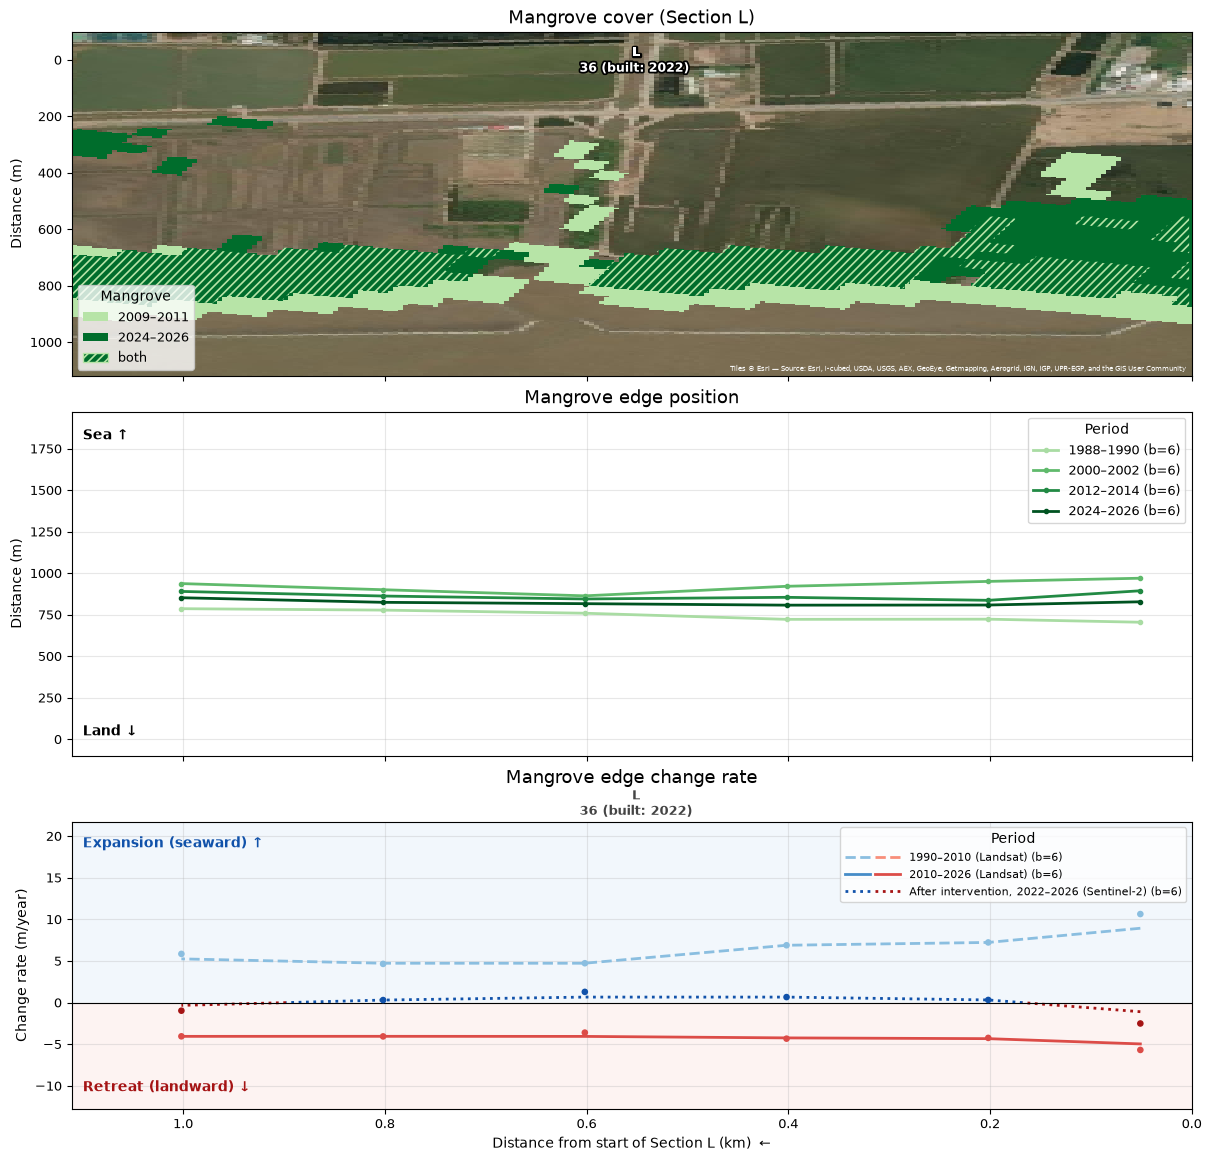

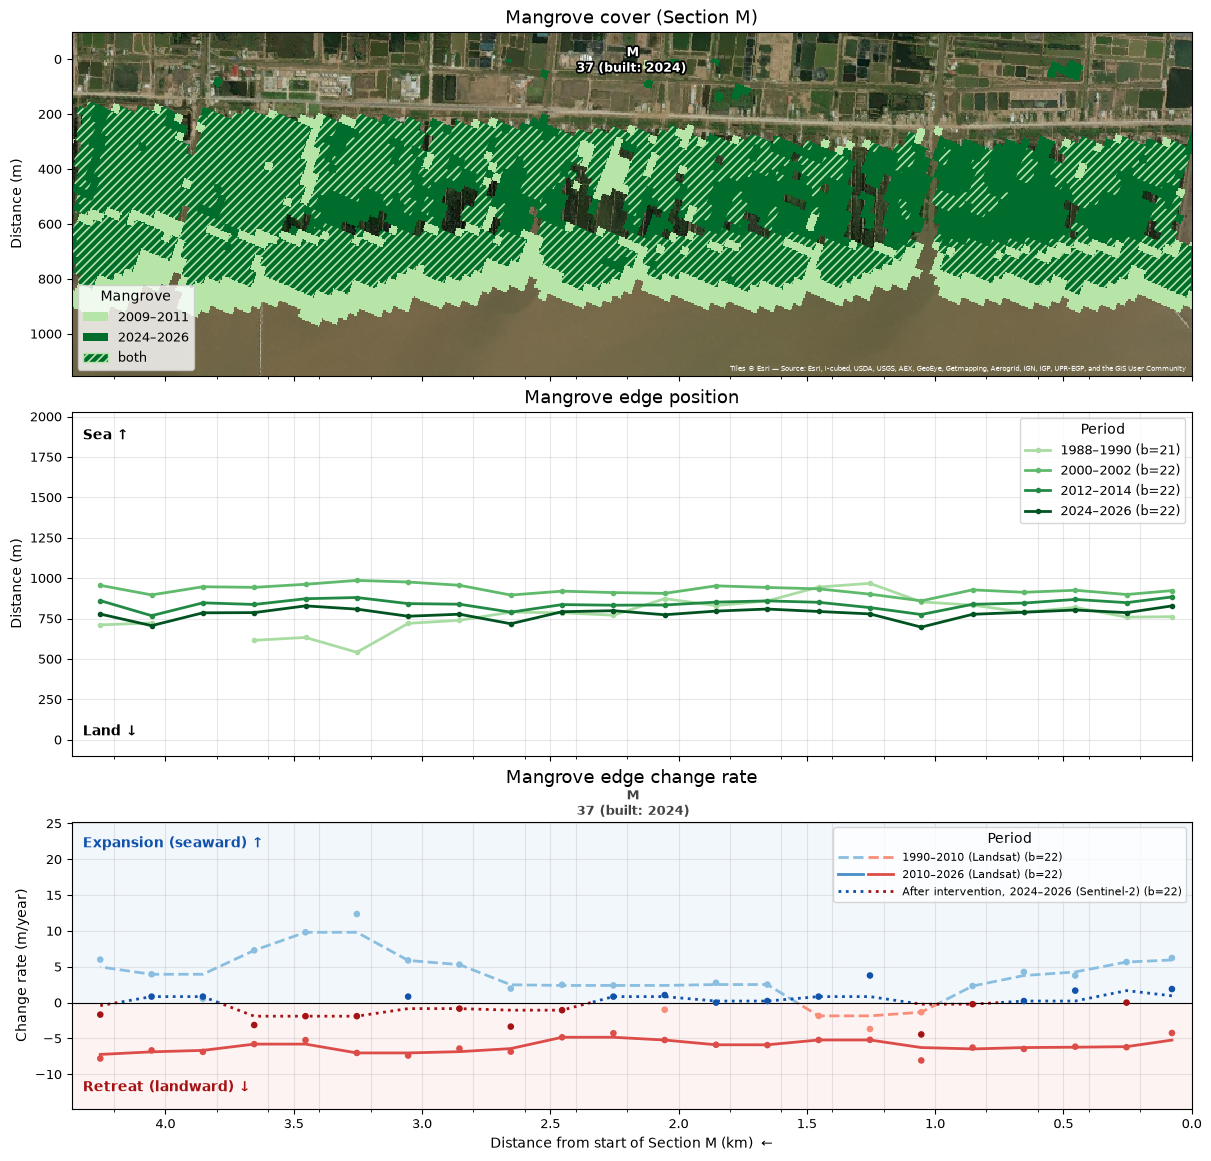

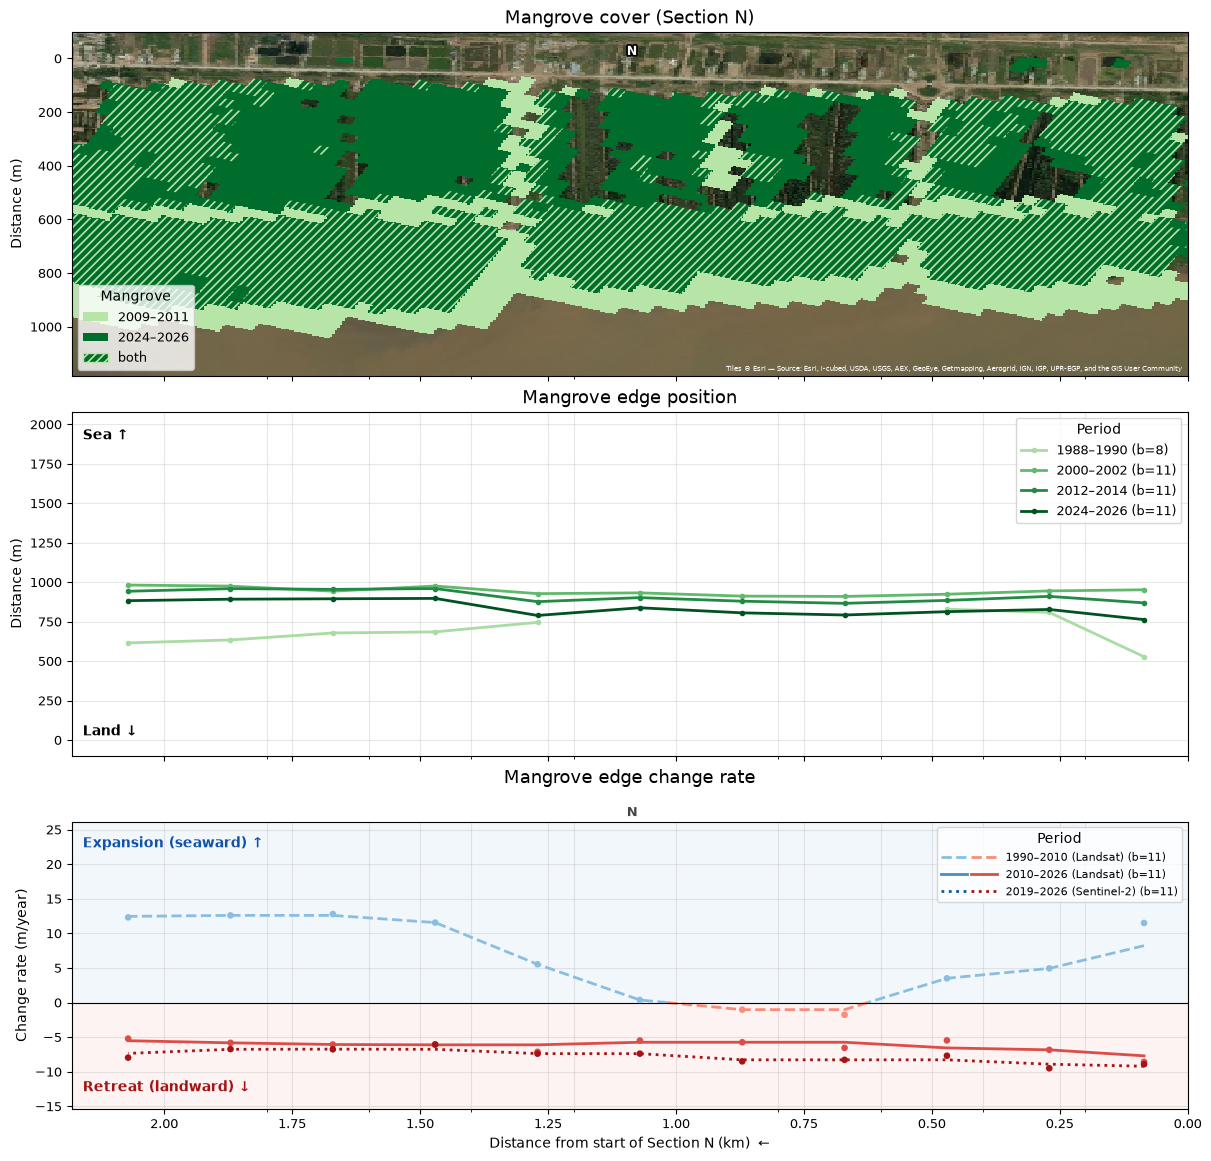

In [55]:
for sector in ORDER:
    plot_sector(sector)

## 8. Edge change rate per section and per intervention

- Section columns: mean of the box rates (Landsat; Sentinel-2 annual for 2019–2026).
- Intervention columns: median of the box rates behind the intervention.
  Before = Landsat 2010–2019, after = Sentinel-2 from the year of construction to 2026.
- `*` = fewer than 25% of the boxes have a rate.

In [56]:
def cell(rates, total, median=False):
    n = rates.notna().sum()
    if n == 0:
        return '–'
    star = '*' if n < 0.25 * total else ''
    value = round(rates.median() if median else rates.mean(), 1) + 0.0
    return f'{value:+.1f}{star}'


rows = []
for site, sector in SECTORS.items():
    site_df = df[df['site'] == site]
    land_df = site_df[site_df['sensor'] == 'landsat']
    s2_df = site_df[site_df['sensor'] == 's2_annual']
    s2_first, s2_last = s2_df['period'].min(), s2_df['period'].max()

    section = {name: box_rates(land_df, first, last) for name, first, last in WINDOWS}
    section[f'{s2_first}–{s2_last} Sentinel-2'] = box_rates(s2_df, s2_first, s2_last)
    most = max(rates.notna().sum() for rates in section.values())
    section_cells = {f'{name} (m/yr)': cell(rates, most) for name, rates in section.items()}

    boxes = site_df.drop_duplicates('x_mid').set_index('x_mid')['intervention']
    built_here = [name for name in boxes.unique() if name in BUILT and name not in CANAL_MOUTH]
    if not built_here:
        rows.append({'section': short_label(sector), **section_cells, 'intervention': '–', 'type': '–',
                     'built': '–', 'before 2010–2019 (m/yr)': '–', 'after construction (m/yr)': '–',
                     'change (m/yr)': '–'})
        continue

    for intervention in built_here:
        here = boxes.index[boxes == intervention]
        built = BUILT[intervention]
        before = section['2010–2019'].reindex(here)
        after = box_rates(s2_df[s2_df['x_mid'].isin(here)], built, s2_last)
        both = before.notna().any() and after.notna().any()
        letter = SUBSECTIONS.get((sector, intervention), sector)
        rows.append({
            'section': short_label(sector),
            **section_cells,
            'intervention': f'{intervention} ({letter})' if len(sector) > 1 else intervention,
            'type': TYPES[intervention],
            'built': built,
            'before 2010–2019 (m/yr)': cell(before, len(here), median=True),
            'after construction (m/yr)': cell(after, len(here), median=True),
            'change (m/yr)': f'{round(after.median() - before.median(), 1) + 0.0:+.1f}' if both else '–',
        })

results = pd.DataFrame(rows)
if SAVE:
    results.to_csv(os.path.join(table_dir, 'results_per_section.csv'), index=False)
results

,section,1988–2010 (m/yr),2010–2019 (m/yr),2010–2026 (m/yr),2019–2026 Sentinel-2 (m/yr),intervention,type,built,before 2010–2019 (m/yr),after construction (m/yr),change (m/yr)
0,A,+1.6,-4.0,-7.1,-14.8,38B,PRBW,2024,-6.3,-1.5,+4.8
1,B,+14.0,-1.9,+1.4,+3.6,38A,PRBW,2024,-3.1,+2.9,+5.9
2,C,+5.3,+54.1,+35.2,+6.2,–,–,–,–,–,–
3,D–E,+1.2,-6.1,-5.9,-9.1,34A (E),PRBW,2023,-8.9,+0.1,+9.0
4,D–E,+1.2,-6.1,-5.9,-9.1,34B (D),PRBW,2020,-6.8,-9.4,-2.7
5,F,-5.5,-0.3,-2.7,-8.1,35,PRBW,2023,-0.4,-6.0,-5.7
6,G,-1.3,-0.1,-3.4,-7.8,–,–,–,–,–,–
7,H–K,+8.2,-5.9,-5.3,-5.6,49A (K),PRBW,2025,-8.0,–,–
8,H–K,+8.2,-5.9,-5.3,-5.6,49D (H),PRBW,2020,-7.2,-0.6,+6.6
9,L,+6.7,-5.9,-4.3,-3.1,36,SCBW,2022,-6.0,+0.3,+6.3


## 9. Turning period of the seaward edge

The period in which the edge was most seaward, per box. Only boxes with an edge in at least `MIN_PERIODS_TURN`
of the 13 Landsat periods. The edge is first smoothed over time with a running median over 3 periods.
Per section, the table gives the median over the boxes and the 25th and 75th percentile.

In [57]:
rows = []
for site, sector in SECTORS.items():
    edges = landsat[landsat['site'] == site].pivot_table(index='bin', columns='period', values='edge')
    edges = edges[edges.notna().sum(axis=1) >= MIN_PERIODS_TURN]
    smooth = edges.T.rolling(3, center=True, min_periods=2).median().T
    peak = smooth.idxmax(axis=1)
    rows.append({
        'section': short_label(sector),
        'boxes': len(peak),
        'most seaward (median)': period_label(int(peak.quantile(0.5, interpolation='nearest'))),
        '25%': period_label(int(peak.quantile(0.25, interpolation='nearest'))),
        '75%': period_label(int(peak.quantile(0.75, interpolation='nearest'))),
    })

turning = pd.DataFrame(rows)
if SAVE:
    turning.to_csv(os.path.join(table_dir, 'turning_period.csv'), index=False)
turning

,section,boxes,most seaward (median),25%,75%
0,A,20,1994–1996,1988–1990,1997–1999
1,B,42,2006–2008,1988–1990,2024–2026
2,C,79,2024–2026,2018–2020,2024–2026
3,D–E,18,2003–2005,2003–2005,2006–2008
4,F,15,1994–1996,1991–1993,1994–1996
5,G,14,1994–1996,1994–1996,1994–1996
6,H–K,16,1997–1999,1997–1999,1997–1999
7,L,6,2000–2002,1997–1999,2003–2005
8,M,22,1997–1999,1997–1999,1997–1999
9,N,11,2000–2002,1997–1999,2003–2005


## 10. Belt width

Share of the boxes (%) with a belt narrower than `MIN_BELT`, per section and per zone (Landsat).

In [58]:
zone_of = {sector: zone for zone, sectors in ZONES.items() for sector in sectors}
belt = landsat.pivot_table(index=['sector', 'bin'], columns='period', values='width_m')[PERIODS]
narrow = belt < MIN_BELT
sector_of_row = belt.index.get_level_values('sector')

narrow_sector = narrow.groupby(sector_of_row).mean().mul(100).loc[ORDER].round(0)
narrow_zone = narrow.groupby(sector_of_row.map(zone_of)).mean().mul(100).loc[list(ZONES)].round(0)
narrow_sector.index = narrow_sector.index.map(short_label)
narrow_zone.index = [f'{zone} (all)' for zone in ['A–B', 'C', 'D–N']]
narrow_table = pd.concat([narrow_sector, narrow_zone])
narrow_table.columns = [period_label(period) for period in narrow_table.columns]
if SAVE:
    narrow_table.to_csv(os.path.join(table_dir, f'share_belt_below_{MIN_BELT}m.csv'))
narrow_table

,1988–1990,2000–2002,2012–2014,2024–2026
A,20.0,0.0,0.0,0.0
B,40.0,17.0,10.0,0.0
C,100.0,100.0,97.0,36.0
D–E,100.0,100.0,100.0,100.0
F,100.0,100.0,100.0,100.0
G,100.0,100.0,100.0,100.0
H–K,100.0,47.0,100.0,82.0
L,100.0,33.0,100.0,100.0
M,100.0,59.0,32.0,73.0
N,100.0,0.0,0.0,18.0


Mean belt width per zone and period: total mangrove area / total coast length.

In [59]:
zones = landsat.groupby([landsat['sector'].map(zone_of), 'period']).agg(
    mangrove_ha=('mangrove_ha', 'sum'),
    length_m=('piece_m', 'sum'),
)
zones.index.names = ['zone', 'period']
zones['width_m'] = zones['mangrove_ha'] * 10000 / zones['length_m']

width_table = zones['width_m'].unstack('zone')[list(ZONES)].round(0)
width_table.index = width_table.index.map(period_label)
if SAVE:
    width_table.to_csv(os.path.join(table_dir, 'belt_width_per_zone_m.csv'))
width_table

zone,A–B,C,DE–N
period,,,
1988–1990,735.0,4.0,109.0
1991–1993,503.0,0.0,221.0
1994–1996,572.0,2.0,311.0
1997–1999,643.0,18.0,283.0
2000–2002,1092.0,106.0,281.0
2003–2005,1087.0,123.0,247.0
2006–2008,996.0,131.0,239.0
2009–2011,1092.0,125.0,255.0
2012–2014,1008.0,193.0,279.0


Mangrove area (ha) inside the boxes, per zone and period.

In [60]:
area_table = zones['mangrove_ha'].unstack('zone')[list(ZONES)]
area_table['Total'] = area_table.sum(axis=1)
area_table = area_table.round(0)
area_table.index = area_table.index.map(period_label)
if SAVE:
    area_table.to_csv(os.path.join(table_dir, 'mangrove_area_per_zone_ha.csv'))
area_table

zone,A–B,C,DE–N,Total
period,,,,
1988–1990,910.0,12.0,258.0,1180.0
1991–1993,622.0,1.0,521.0,1144.0
1994–1996,709.0,6.0,733.0,1447.0
1997–1999,795.0,48.0,667.0,1511.0
2000–2002,1352.0,289.0,661.0,2302.0
2003–2005,1346.0,336.0,581.0,2262.0
2006–2008,1233.0,356.0,563.0,2152.0
2009–2011,1352.0,340.0,601.0,2293.0
2012–2014,1249.0,526.0,657.0,2432.0


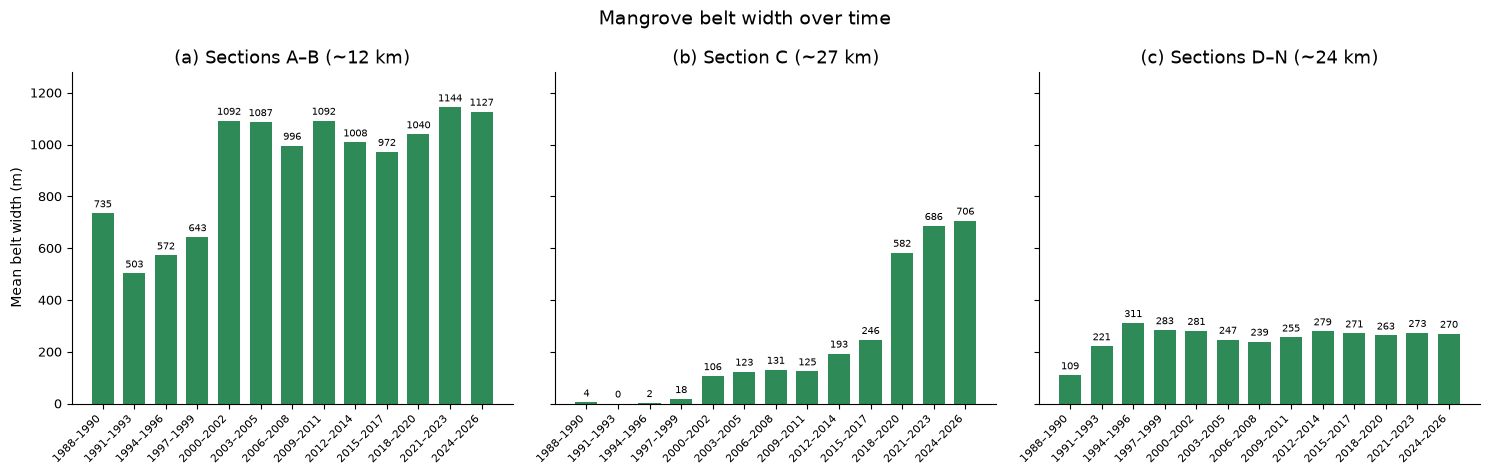

In [61]:
periods = sorted(landsat['period'].unique())
x = np.arange(len(periods))
top = zones['width_m'].max()

fig, axes = plt.subplots(1, len(ZONES), figsize=(15, 4.8), sharey=True)
for ax, zone, letter in zip(axes, ZONES, 'abc'):
    part = zones.loc[zone]
    ax.bar(x, part['width_m'], width=0.7, color=GREEN)
    for xi, value in zip(x, part['width_m']):
        ax.text(xi, value + top * 0.02, f'{value:.0f}', ha='center', fontsize=7)

    first, last = ZONES[zone][0][0], ZONES[zone][-1][-1]
    name = f'Section {first}' if first == last else f'Sections {first}–{last}'
    km = part['length_m'].iloc[0] / 1000
    ax.set_title(f'({letter}) {name} (~{km:.0f} km)')
    ax.set_xticks(x, [period_label(p) for p in periods], rotation=45, ha='right', fontsize=8)
    ax.set_ylim(0, top * 1.12)
    ax.spines[['top', 'right']].set_visible(False)

axes[0].set_ylabel('Mean belt width (m)')
fig.suptitle('Mangrove belt width over time', fontsize=14)
fig.tight_layout()
if SAVE:
    fig.savefig(os.path.join(fig_dir, 'history_zones.png'), dpi=300, bbox_inches='tight')
plt.show()

Mean belt width per section for the periods in `PERIODS`, next to a map of the sections.
The map is the 2024–2026 study area image, rotated so the coast runs from top (A, north-east) to bottom (N, south-west).

In [62]:
sectors = landsat.groupby(['sector', 'period']).agg(
    mangrove_ha=('mangrove_ha', 'sum'),
    length_m=('piece_m', 'sum'),
)
sectors['width_m'] = sectors['mangrove_ha'] * 10000 / sectors['length_m']

sector_width = sectors['width_m'].unstack('period').loc[ORDER].round(0)
sector_width.index = sector_width.index.map(short_label)
sector_width.columns = sector_width.columns.map(period_label)
if SAVE:
    sector_width.to_csv(os.path.join(table_dir, 'belt_width_per_section_m.csv'))
sector_width

period,1988–1990,1991–1993,1994–1996,1997–1999,2000–2002,2003–2005,2006–2008,2009–2011,2012–2014,2015–2017,2018–2020,2021–2023,2024–2026
sector,,,,,,,,,,,,,
A,1083.0,874.0,1034.0,1043.0,1456.0,1407.0,1194.0,1237.0,1243.0,1245.0,1289.0,1380.0,1345.0
B,570.0,326.0,353.0,453.0,919.0,935.0,902.0,1024.0,897.0,842.0,922.0,1032.0,1024.0
C,4.0,0.0,2.0,18.0,106.0,123.0,131.0,125.0,193.0,246.0,582.0,686.0,706.0
D–E,8.0,1.0,9.0,5.0,43.0,94.0,118.0,117.0,86.0,72.0,79.0,60.0,62.0
F,48.0,13.0,73.0,66.0,19.0,34.0,67.0,68.0,86.0,83.0,106.0,122.0,134.0
G,56.0,129.0,222.0,202.0,219.0,222.0,220.0,225.0,274.0,236.0,262.0,282.0,265.0
H–K,153.0,395.0,522.0,464.0,444.0,418.0,382.0,305.0,291.0,283.0,282.0,330.0,335.0
L,178.0,405.0,520.0,521.0,565.0,242.0,219.0,205.0,206.0,224.0,192.0,175.0,179.0
M,279.0,471.0,630.0,562.0,484.0,374.0,349.0,455.0,524.0,529.0,462.0,472.0,456.0


Mangrove area (ha) inside the boxes, per section and period.

In [63]:
sector_area = sectors['mangrove_ha'].unstack('period').loc[ORDER].round(0)
sector_area.index = sector_area.index.map(short_label)
sector_area.columns = sector_area.columns.map(period_label)
if SAVE:
    sector_area.to_csv(os.path.join(table_dir, 'mangrove_area_per_section_ha.csv'))
sector_area

period,1988–1990,1991–1993,1994–1996,1997–1999,2000–2002,2003–2005,2006–2008,2009–2011,2012–2014,2015–2017,2018–2020,2021–2023,2024–2026
sector,,,,,,,,,,,,,
A,431.0,348.0,412.0,415.0,580.0,560.0,475.0,492.0,495.0,496.0,513.0,549.0,536.0
B,479.0,274.0,297.0,380.0,772.0,785.0,757.0,860.0,754.0,708.0,774.0,867.0,860.0
C,12.0,1.0,6.0,48.0,289.0,336.0,356.0,340.0,526.0,669.0,1586.0,1868.0,1924.0
D–E,4.0,1.0,5.0,3.0,21.0,46.0,58.0,57.0,42.0,35.0,39.0,29.0,30.0
F,22.0,6.0,33.0,30.0,9.0,15.0,31.0,31.0,39.0,38.0,49.0,56.0,61.0
G,17.0,40.0,69.0,63.0,68.0,69.0,68.0,70.0,85.0,73.0,81.0,88.0,82.0
H–K,51.0,132.0,175.0,155.0,148.0,140.0,128.0,102.0,97.0,95.0,94.0,110.0,112.0
L,20.0,45.0,57.0,58.0,62.0,27.0,24.0,23.0,23.0,25.0,21.0,19.0,20.0
M,122.0,205.0,275.0,245.0,211.0,163.0,152.0,198.0,228.0,231.0,201.0,206.0,199.0


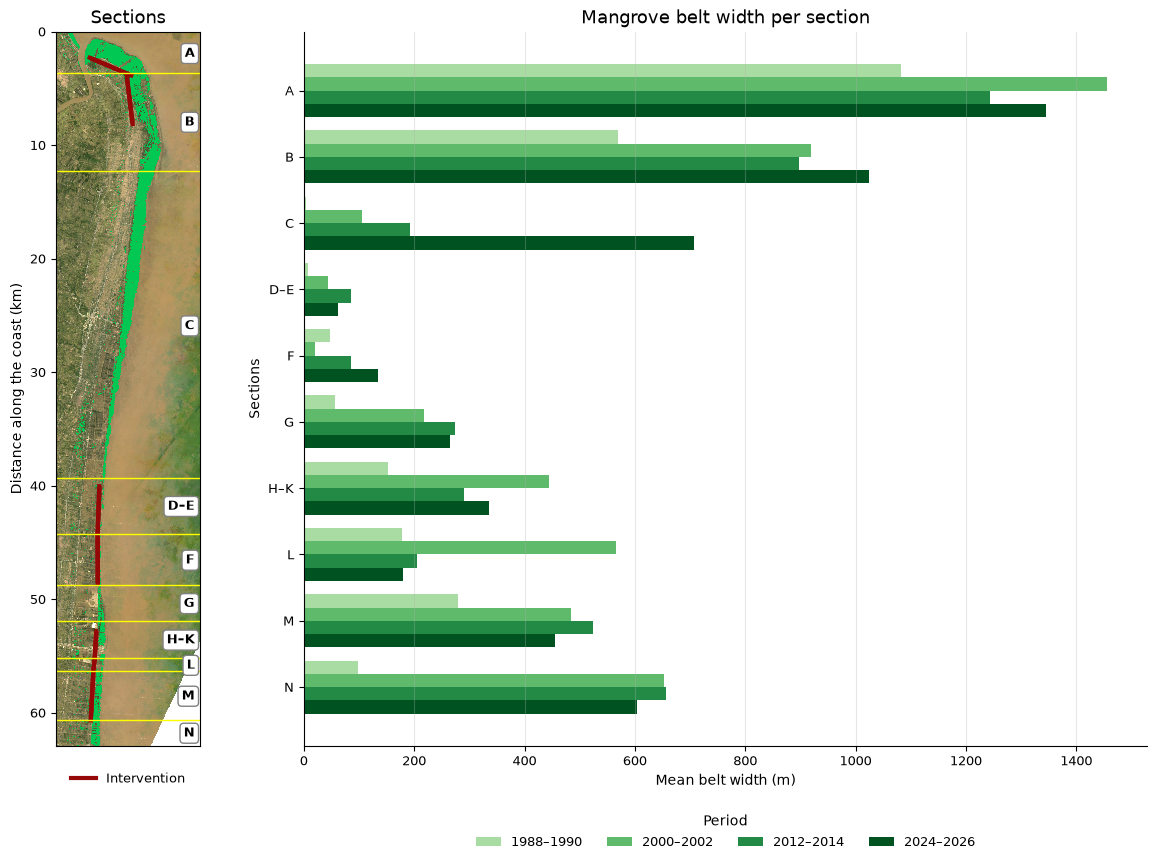

In [64]:
# Frame for the whole coast: from the north-east end of A to the south-west end of N
corners = np.vstack([box['corners'] for site in SECTORS for box in box_corners(site)])
first, last = site_frame(SITE_OF[ORDER[0]]), site_frame(SITE_OF[ORDER[-1]])
north_end = first['origin']
south_end = last['origin'] + last['along'] * last['length']
along = (south_end - north_end) / np.linalg.norm(south_end - north_end)
seaward = np.array([-along[1], along[0]])
s = corners @ along
d = corners @ seaward
coast = {'origin': s.min() * along, 'along': along, 'seaward': seaward, 'length': s.max() - s.min()}
d_min, d_max = d.min() - 3000, d.max() + 3000

map_file = find_file(f'intro_mangrove_{PERIODS[-1]}.tif')
with rasterio.open(map_file) as src:
    bands = list(src.descriptions)
layers, _ = sample_map(map_file, bands, coast, d_min, d_max, step=30)
rgb = np.dstack(layers).transpose(1, 0, 2) / 255
rgb[np.isnan(rgb)] = 1

fig, (ax_map, ax) = plt.subplots(1, 2, figsize=(12, 9), gridspec_kw={'width_ratios': [1, 3]})

# Map: red = boxes with an intervention, yellow = section boundaries
length_km = coast['length'] / 1000
ax_map.imshow(rgb, extent=(d_min / 1000, d_max / 1000, length_km, 0), interpolation='nearest')
for site, sector in SECTORS.items():
    boxes = box_corners(site)
    frame = site_frame(site)
    interventions = df[df['site'] == site].drop_duplicates('x_m').set_index('x_m')['intervention']
    for box in boxes:
        if interventions.get(box['x_m'], 'none') == 'none':
            continue
        land_side = box['corners'][np.argsort(box['corners'] @ frame['seaward'])[:2]]
        ax_map.plot(land_side @ seaward / 1000, (land_side @ along - s.min()) / 1000, color='#960707', linewidth=3)

    ends = np.vstack([box['corners'] for box in boxes]) @ along
    top, bottom = (ends.min() - s.min()) / 1000, (ends.max() - s.min()) / 1000
    if sector != ORDER[0]:
        ax_map.axhline(top, color='yellow', linewidth=1)
    ax_map.text(d_max / 1000 - 0.5, (top + bottom) / 2, short_label(sector), ha='right', va='center', fontsize=9,
                fontweight='bold', bbox=dict(boxstyle='round', facecolor='white', edgecolor='grey'))

ax_map.set_xticks([])
ax_map.set_ylabel('Distance along the coast (km)')
ax_map.set_title('Sections')
ax_map.legend(handles=[Line2D([], [], color='#960707', linewidth=3, label='Intervention')],
              loc='upper center', bbox_to_anchor=(0.5, -0.02), frameon=False)

# Bars: belt width per section
y = np.arange(len(ORDER))
height = 0.8 / len(PERIODS)
greens = plt.cm.Greens(np.linspace(0.35, 0.95, len(PERIODS)))
for i, period in enumerate(PERIODS):
    widths = sectors['width_m'].xs(period, level='period').reindex(ORDER)
    offset = (i - (len(PERIODS) - 1) / 2) * height
    ax.barh(y + offset, widths, height=height, color=greens[i], label=period_label(period))

ax.set_yticks(y, [short_label(sector) for sector in ORDER])
ax.invert_yaxis()
ax.set_ylabel('Sections')
ax.set_xlabel('Mean belt width (m)')
ax.set_title('Mangrove belt width per section')
ax.legend(title='Period', loc='upper center', bbox_to_anchor=(0.5, -0.08), ncol=len(PERIODS), frameon=False)
ax.grid(axis='x', alpha=0.3)
ax.spines[['top', 'right']].set_visible(False)

fig.tight_layout(rect=(0, 0.03, 1, 1))
if SAVE:
    fig.savefig(os.path.join(fig_dir, 'mangrove_belt_width_per_section.png'), dpi=300, bbox_inches='tight')
plt.show()

## 11. Method checks

Accuracy of the thresholds at the 512 reference points (period 2025), with a 95% Wilson confidence interval.
The validation half = points with `random` ≥ 0.5 (random number from GEE, seed 42).

In [65]:
def wilson(k, n, z=1.96):
    p = k / n
    centre = (p + z**2 / (2 * n)) / (1 + z**2 / n)
    half = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / (1 + z**2 / n)
    return 100 * (centre - half), 100 * (centre + half)


rows = []
for sensor, (mvi, ndvi) in THRESHOLDS.items():
    points = pd.read_csv(find_file(f'calibration_{sensor}.csv'))
    for subset, part in [('all points', points), ('validation half', points[points['random'] >= 0.5])]:
        predicted = (part['mvi'] > mvi) & (part['ndvi'] > ndvi)
        actual = part['class'] == 1
        tp, tn = (predicted & actual).sum(), (~predicted & ~actual).sum()
        fp, fn = (predicted & ~actual).sum(), (~predicted & actual).sum()
        low, high = wilson(tp + tn, len(part))
        rows.append({
            'sensor': sensor,
            'thresholds': f'MVI > {mvi}, NDVI > {ndvi}',
            'points': subset,
            'n': len(part),
            'overall_%': 100 * (tp + tn) / len(part),
            'ci_low_%': low,
            'ci_high_%': high,
            'producers_%': 100 * tp / (tp + fn),
            'users_%': 100 * tp / (tp + fp),
        })

accuracy = pd.DataFrame(rows).round(1)
if SAVE:
    accuracy.to_csv(os.path.join(table_dir, 'accuracy.csv'), index=False)
accuracy

,sensor,thresholds,points,n,overall_%,ci_low_%,ci_high_%,producers_%,users_%
0,landsat,"MVI > 4, NDVI > 0.3",all points,512,95.1,92.9,96.7,91.4,98.7
1,landsat,"MVI > 4, NDVI > 0.3",validation half,259,95.8,92.6,97.6,93.2,98.4
2,s2,"MVI > 2.75, NDVI > 0.3",all points,512,98.2,96.7,99.1,97.3,99.2
3,s2,"MVI > 2.75, NDVI > 0.3",validation half,259,97.7,95.0,98.9,96.2,99.2


MVI of the reference points and the chosen thresholds.

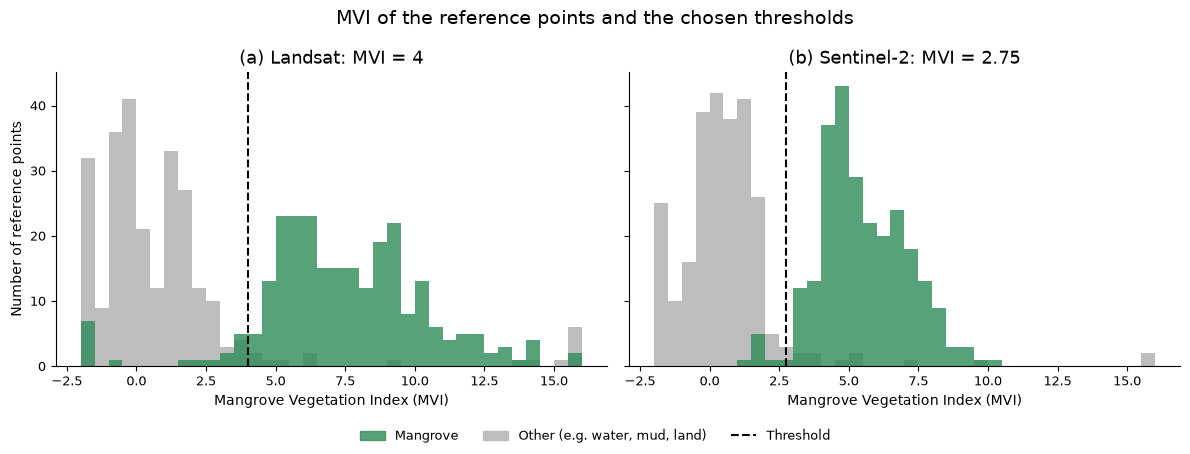

In [66]:
MVI_RANGE = (-2, 16)
bins = np.linspace(*MVI_RANGE, 37)
names = {'landsat': '(a) Landsat', 's2': '(b) Sentinel-2'}

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)
for ax, (sensor, (mvi, ndvi)) in zip(axes, THRESHOLDS.items()):
    points = pd.read_csv(find_file(f'calibration_{sensor}.csv'))
    values = points['mvi'].clip(*MVI_RANGE)
    ax.hist(values[points['class'] == 0], bins=bins, color='#bdbdbd')
    ax.hist(values[points['class'] == 1], bins=bins, color=GREEN, alpha=0.8)
    ax.axvline(mvi, color='black', linestyle='--', linewidth=1.5)
    ax.set_title(f'{names[sensor]}: MVI = {mvi}')
    ax.set_xlabel('Mangrove Vegetation Index (MVI)')
    ax.spines[['top', 'right']].set_visible(False)

axes[0].set_ylabel('Number of reference points')
legend = [Patch(color=GREEN, alpha=0.8, label='Mangrove'),
          Patch(color='#bdbdbd', label='Other (e.g. water, mud, land)'),
          Line2D([], [], color='black', linestyle='--', linewidth=1.5, label='Threshold')]
fig.legend(handles=legend, loc='lower center', ncol=3, frameon=False)
fig.suptitle('MVI of the reference points and the chosen thresholds', fontsize=14)
fig.tight_layout(rect=(0, 0.06, 1, 1))
if SAVE:
    fig.savefig(os.path.join(fig_dir, 'mvi_thresholds.png'), dpi=300, bbox_inches='tight')
plt.show()

Landsat vs. Sentinel-2: belt width per box in the three periods measured by both sensors (2019, 2022, 2025).

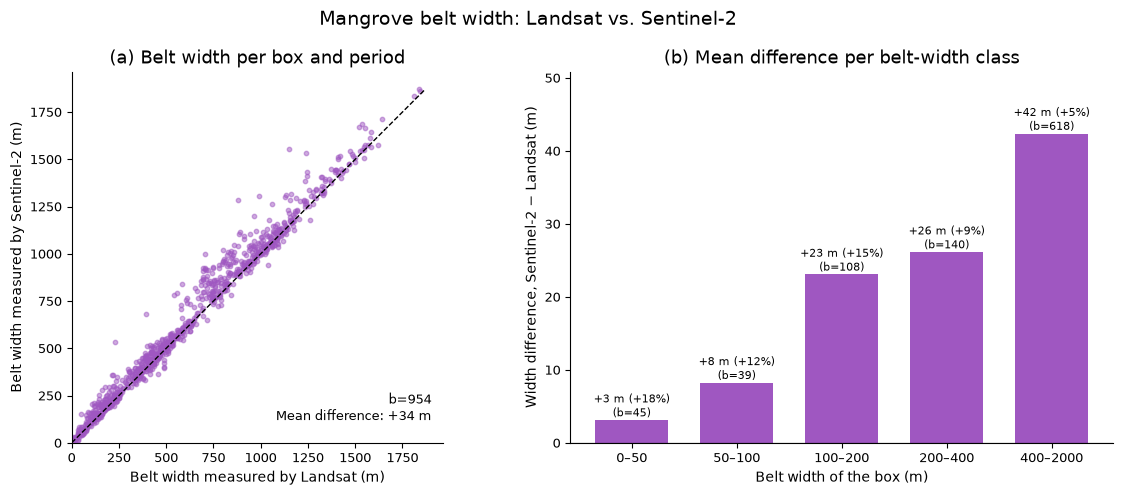

In [67]:
s2_periods = sorted(df.loc[df['sensor'] == 's2', 'period'].unique())
same = df[df['sensor'].isin(['landsat', 's2']) & df['period'].isin(s2_periods)]
pairs = same.pivot_table(index=['sector', 'bin', 'period'], columns='sensor', values='width_m').dropna()
pairs['difference'] = pairs['s2'] - pairs['landsat']
pairs['mean_width'] = (pairs['s2'] + pairs['landsat']) / 2

classes = pd.cut(pairs['mean_width'], [0, 50, 100, 200, 400, 2000])
by_width = pairs.groupby(classes, observed=False).agg(
    mean=('difference', 'mean'), count=('difference', 'size'), width=('mean_width', 'mean')).dropna()
by_width['percent'] = 100 * by_width['mean'] / by_width['width']
if SAVE:
    by_width.round(1).to_csv(os.path.join(table_dir, 'landsat_vs_s2_by_width.csv'))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

# (a) Every box and period measured by both sensors
ax1.scatter(pairs['landsat'], pairs['s2'], s=10, alpha=0.5, color=S2_COLOUR)
top = pairs[['landsat', 's2']].max().max()
ax1.plot([0, top], [0, top], color='black', linestyle='--', linewidth=1)
ax1.set_xlim(0, top * 1.05)
ax1.set_ylim(0, top * 1.05)
ax1.set_aspect('equal')
ax1.set_xlabel('Belt width measured by Landsat (m)')
ax1.set_ylabel('Belt width measured by Sentinel-2 (m)')
ax1.set_title('(a) Belt width per box and period')
ax1.text(0.97, 0.05, f'b={len(pairs)}\nMean difference: {pairs["difference"].mean():+.0f} m',
         transform=ax1.transAxes, ha='right', va='bottom', fontsize=9)

# (b) How much wider Sentinel-2 measures, per belt width class
labels = [f'{int(interval.left)}–{int(interval.right)}' for interval in by_width.index]
ax2.bar(labels, by_width['mean'], color=S2_COLOUR, width=0.7)
for i, (value, percent, count) in enumerate(zip(by_width['mean'], by_width['percent'], by_width['count'])):
    ax2.text(i, value, f'{value:+.0f} m ({percent:+.0f}%)\n(b={count})', ha='center', va='bottom', fontsize=8)
ax2.axhline(0, color='black', linewidth=0.8)
ax2.set_ylim(0, by_width['mean'].max() * 1.2)
ax2.set_xlabel('Belt width of the box (m)')
ax2.set_ylabel('Width difference, Sentinel-2 − Landsat (m)')
ax2.set_title('(b) Mean difference per belt-width class')

for ax in (ax1, ax2):
    ax.spines[['top', 'right']].set_visible(False)
fig.suptitle('Mangrove belt width: Landsat vs. Sentinel-2', fontsize=14)
fig.tight_layout()
if SAVE:
    fig.savefig(os.path.join(fig_dir, 'landsat_vs_s2.png'), dpi=300, bbox_inches='tight')
plt.show()